<a href="https://colab.research.google.com/github/tluong1507/TrinhLuong_DTSC3020_Fall2026/blob/main/DTSC3020_Lesson8_Lecture_note_10192026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<style>
.jp-RenderedHTMLCommon h1 { color: #0b6b3a; border-bottom: 2px solid #dcefe5; padding-bottom: 6px; }
.jp-RenderedHTMLCommon h2 { color: #0e5f43; margin-top: 28px; }
.jp-RenderedHTMLCommon h3 { color: #205b85; }
.callout { border-left: 7px solid #0b6b3a; background: #f3fbf5; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.warning { border-left: 7px solid #b45309; background: #fff8e6; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.activity { border-left: 7px solid #2563eb; background: #f2f6ff; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.checkpoint { border-left: 7px solid #7c3aed; background: #f8f5ff; padding: 14px 18px; margin: 16px 0; border-radius: 8px; }
.quiz { border: 1px solid #d8e2ea; background: #fbfdff; padding: 14px 18px; margin: 16px 0; border-radius: 10px; }
.figcap { font-size: 0.9em; color: #52616b; margin-top: 6px; }
.figure { margin: 18px 0 24px 0; padding: 8px; background: #ffffff; border: 1px solid #d8e2ea; border-radius: 14px; }
.small { font-size: 0.92em; color: #52616b; }
</style>

# DTSC 3020: Introduction to Computation with Python
## Lesson 8: Files Handling and Testing Code

**Instructor:** Dr. Haihua Chen
**Department of Data Science, University of North Texas**

<div class="callout">
<b>Big idea:</b> Real data lives in files, and real programs must be trusted. Today you will learn to read and write files safely, handle things that go wrong, and <b>prove</b> that your code works with tests. These are exactly the skills you need to verify AI-generated code.
</div>

<div class="figure">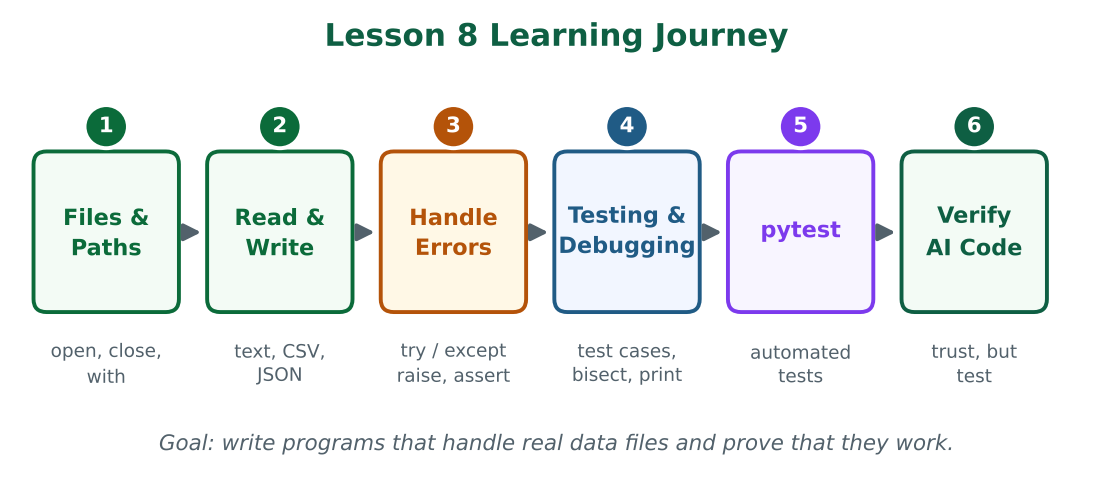</div>

## Lesson 8 Learning Objectives

By the end of this lesson, you should be able to:

1. Explain why programs need files and how absolute and relative paths work.
2. Open, read, write, append, and close text files using `open()` and the `with` statement.
3. Choose the correct file mode (`"r"`, `"w"`, `"a"`, `"x"`) and avoid accidentally erasing data.
4. Read and write structured data in **CSV** and **JSON** formats.
5. Recognize common Python exceptions and handle them with `try` / `except` / `else` / `finally`.
6. Use `raise` and `assert` to make functions defensive.
7. Write a specification and design test cases (typical, **boundary**, empty, invalid) using black-box and glass-box thinking.
8. Read a traceback and debug with a systematic workflow: reproduce, simplify, hypothesize, experiment, fix, re-test.
9. Write automated unit tests with **pytest** (`assert`, `approx`, `raises`, `parametrize`, `tmp_path`, fixtures), and use tests to check AI-generated code.

# Part 0. Warm-Up: Where Does Our Data Go?

So far, every variable we created disappeared when the program ended. Run the next cell, then restart the kernel (or close the notebook) and think about what happens to `scores`.

In [ ]:
scores = [88, 92, 79]
print("Scores in memory:", scores)
# When the program ends, this list is gone. How can we keep it?

<div class="checkpoint">
<b>Checkpoint:</b> Where would a data scientist store survey results, sensor readings, or text collected from the web so they are still there tomorrow? Write down two ideas before moving on.
</div>

# Part 1. Why Files? Persistent Data

Variables live in **memory** and vanish when the program stops. **Files** store data on disk, so it is **persistent**. Files are also how programs receive input from, and send results to, other people and other tools.

**Reading:** [Reading and Writing Files — Python Docs](https://docs.python.org/3/tutorial/inputoutput.html#reading-and-writing-files)

| File type | Extension | Typical use in data science |
|---|---|---|
| Plain text | `.txt` | Documents, logs, transcripts, text for NLP |
| CSV (comma-separated values) | `.csv` | Tables: surveys, spreadsheets, exported databases |
| JSON (JavaScript Object Notation) | `.json` | Web/API data, nested records, configuration |
| Excel | `.xlsx` | Business spreadsheets (read with `pandas`) |
| XML | `.xml` | Older structured data, some archives and metadata |
| Binary | `.png`, `.pkl`, ... | Images, models, other non-text data |

<div class="callout">
<b>Lesson focus:</b> We start with plain text, then move to CSV and JSON, the two formats you will use most often in this course.
</div>

## Setup: A Practice Folder

Run this cell once. It creates a folder named `lesson8_data` next to your notebook. All our practice files go there so we never mix them with your other work.

In [ ]:
from pathlib import Path
import os

DATA_DIR = Path("lesson8_data")
DATA_DIR.mkdir(exist_ok=True)      # create the folder if it does not exist yet
print("Our practice folder:", DATA_DIR.resolve())

# Part 2. File Paths: Where Is My File?

Python needs to know **where** a file is. The location is called a **path**.

- An **absolute path** gives the full location from the top of the file system, such as `/home/alice/data/scores.txt` (Linux/macOS) or `C:\Users\Alice\data\scores.txt` (Windows).
- A **relative path** starts from the **current working directory** (the folder Python is running in), such as `lesson8_data/scores.txt`.
- If you give only a file name, Python looks in the current working directory.

In [ ]:
print("Current working directory:", os.getcwd())
print("Relative path  :", DATA_DIR / "scores.txt")
print("Absolute path  :", (DATA_DIR / "scores.txt").resolve())

## Building Paths with `pathlib`

Paths are passed around as strings or as `Path` objects. `pathlib.Path` is safer because the `/` operator joins pieces correctly on every operating system.

In [ ]:
p = DATA_DIR / "notes.txt"
print("Path object :", p)
print("File name   :", p.name)
print("Extension   :", p.suffix)
print("Parent      :", p.parent)
print("Exists yet? :", p.exists())

<div class="warning">
<b>Windows backslash trap:</b> In a normal Python string, the backslash <code>\</code> starts an <i>escape sequence</i> (<code>\n</code> = new line, <code>\t</code> = tab). A Windows path like <code>"C:\new_folder\table.txt"</code> is therefore broken. Fix it with a <b>raw string</b> (prefix <code>r</code>), forward slashes, or <code>pathlib</code>.
</div>

In [ ]:
print("C:\new_folder\table.txt")     # \n and \t are interpreted as escapes!
print(r"C:\new_folder\table.txt")    # raw string: backslashes are kept as typed

# Part 3. Opening and Closing Files

Working with a file always follows three steps:

1. **Open** the file. This gives you a *file object* (also called a *file handle*).
2. **Read or write** using the handle.
3. **Close** the file.

<div class="figure">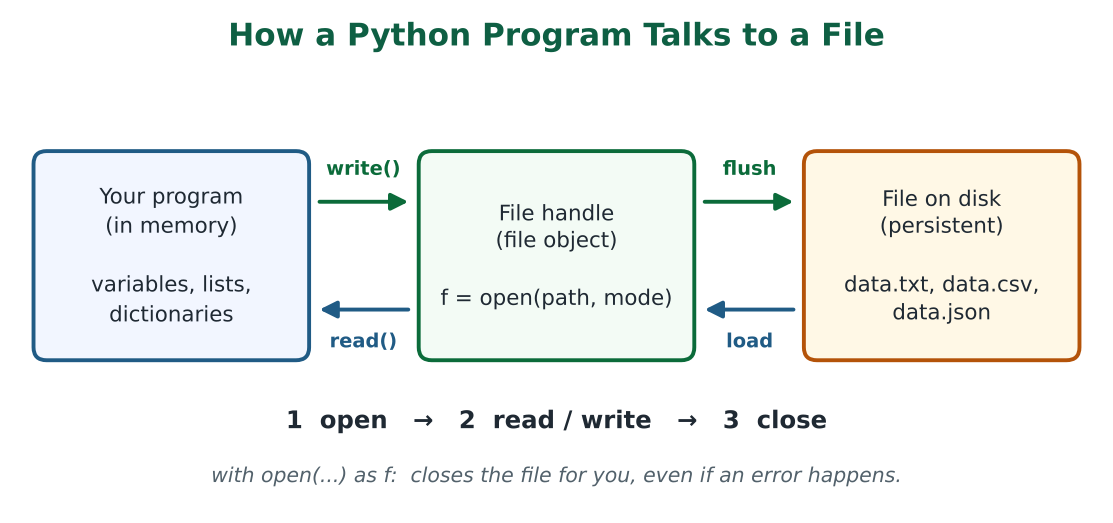<p class="figcap">Concept adapted from Dr. Bill Young's File I/O slides (UT Austin) and the 30 Days of Python file handling chapter.</p></div>

```python
file_handle = open(filename, mode)
```

| Mode | Meaning | If the file does not exist | If the file exists |
|---|---|---|---|
| `"r"` | **Read** (default) | `FileNotFoundError` | Opens at the start |
| `"w"` | **Write** | Creates it | **Erases the old content!** |
| `"a"` | **Append** | Creates it | Adds to the end |
| `"x"` | Exclusive create | Creates it | `FileExistsError` |
| `"t"` | Text mode (default) | | |
| `"b"` | Binary mode (images, etc.) | | |

You can combine them, for example `"rb"` (read binary).

## Our First File

We open a new file in write mode, write two lines, and close it. Notice that `write()` **returns** the number of characters written and does **not** add a new line for you.

In [ ]:
f = open(DATA_DIR / "hello.txt", "w")
count = f.write("Hello DTSC 3020!\n")       # \n is the new-line character
f.write("Files make data persistent.\n")
print("Characters written by the first write():", count)
print("Closed yet?", f.closed)
f.close()
print("Closed yet?", f.closed)

In [ ]:
f = open(DATA_DIR / "hello.txt")    # no mode given, so "r" (read) is used
print(f)                            # the file object, not the content
print(f.read())                     # read() returns the whole file as ONE string
f.close()

<div class="warning">
<b>Why must we close files?</b>
<ul>
<li>Text you write may sit in a buffer and not reach the disk until the file is closed.</li>
<li>An open file can be locked so that other programs cannot use it.</li>
<li>A file opened for writing cannot be read until you close it and reopen it.</li>
<li>It is simply good programming practice. People forget, so Python gives us a safer way:</li>
</ul>
</div>

## The `with` Statement: Close Automatically

`with open(...) as f:` closes the file for you when the indented block ends, **even if an error happens** inside the block. From now on, we use `with` for almost everything.

In [ ]:
with open(DATA_DIR / "hello.txt", encoding="utf-8") as f:
    text = f.read()

print("Closed after the with block?", f.closed)
print(text)

<div class="callout">
<b>Habit to build:</b> Always write <code>encoding="utf-8"</code> when you open text files. Without it, Python uses your computer's default, and the same program can behave differently on Windows, macOS, and Linux.
</div>

# Part 4. Reading Text Files

**Reading:** [30 Days of Python, Day 19: File Handling](https://github.com/Asabeneh/30-Days-Of-Python/blob/master/19_Day_File_handling/19_file_handling.md)

First, let's create a file with some lines of text to read. (These are the opening lines of Edgar Allan Poe's public-domain poem *The Raven*.)

In [ ]:
raven = """Once upon a midnight dreary, while I pondered, weak and weary,
Over many a quaint and curious volume of forgotten lore—
While I nodded, nearly napping, suddenly there came a tapping,
As of some one gently rapping, rapping at my chamber door.
"'Tis some visitor," I muttered, "tapping at my chamber door—
Only this and nothing more."
"""

RAVEN = DATA_DIR / "raven.txt"
with open(RAVEN, "w", encoding="utf-8") as f:
    f.write(raven)
print("Created", RAVEN, "with", len(raven), "characters")

## The Reading Methods

| Method | What it returns |
|---|---|
| `f.read()` | The **entire** remaining content as one string |
| `f.read(k)` | The next `k` characters as a string |
| `f.readline()` | The **next line** as a string (including the `\n`) |
| `f.readlines()` | **All** remaining lines as a list of strings |
| `for line in f:` | One line at a time (best for big files) |

These methods move an internal **file pointer**. `open()` puts the pointer at the beginning, and each read continues from where the last one stopped.

In [ ]:
with open(RAVEN, encoding="utf-8") as f:
    whole = f.read()

print(type(whole))
print("Number of characters:", len(whole))
print("First 60 characters :", repr(whole[:60]))

In [ ]:
with open(RAVEN, encoding="utf-8") as f:
    print("read(10)  ->", repr(f.read(10)))      # first 10 characters
    print("read(10)  ->", repr(f.read(10)))      # the NEXT 10 characters

In [ ]:
with open(RAVEN, encoding="utf-8") as f:
    first = f.readline()
    second = f.readline()
    print("Line 1:", repr(first))
    print("Line 2:", repr(second))
    print("Pointer position:", f.tell())
    f.seek(0)                                    # jump back to the beginning
    print("After seek(0), readline() ->", repr(f.readline()))

In [ ]:
with open(RAVEN, encoding="utf-8") as f:
    lines = f.readlines()

print(type(lines), len(lines), "lines")
print(lines[0])      # note: each line still ends with \n

# A common alternative that removes the \n for you:
with open(RAVEN, encoding="utf-8") as f:
    clean_lines = f.read().splitlines()
print(clean_lines[0])

## Looping Over a File (Best Practice)

A file object is **iterable**: a `for` loop gives you one line at a time without loading the whole file into memory. This matters when a data file has millions of rows.

In [ ]:
with open(RAVEN, encoding="utf-8") as f:
    for line_number, line in enumerate(f, start=1):
        print(f"{line_number:3d}: {line.strip()}")

<div class="checkpoint">
<b>Checkpoint:</b> Change <code>line.strip()</code> to just <code>line</code> and run the cell again. Why do blank lines appear between the poem lines? <i>(Hint: how many new-line characters are printed for each line?)</i>
</div>

## Example: Count Lines and Words

This small function is useful for text analysis. Notice that it has a clear purpose, a docstring (its **specification**), and returns a value instead of only printing. We will test it later.

In [ ]:
def count_lines_and_words(path):
    """Return (number_of_lines, number_of_words) for a text file."""
    lines = 0
    words = 0
    with open(path, encoding="utf-8") as f:
        for line in f:
            lines += 1
            words += len(line.split())
    return lines, words


print(count_lines_and_words(RAVEN))

# Part 5. Writing, Appending, and Deleting Files

**Reading:** File I/O (Slideset 14) — Dr. Bill Young, UT Austin (see sources)

## `"w"` Overwrites, `"a"` Appends

<div class="warning">
<b>Danger:</b> Opening an existing file with <code>"w"</code> <b>erases its content immediately</b>, even if you never write anything. Use <code>"a"</code> to add to the end.
</div>

In [ ]:
path = DATA_DIR / "write_demo.txt"

with open(path, "w", encoding="utf-8") as f:
    f.write("First version\n")

with open(path, "w", encoding="utf-8") as f:      # "w" again: the old line is gone
    f.write("Second version\n")

print("After two 'w' writes:")
print(path.read_text(encoding="utf-8"))

with open(path, "a", encoding="utf-8") as f:      # "a": keep old content, add more
    f.write("Appended line\n")

print("After an 'a' write:")
print(path.read_text(encoding="utf-8"))

## Writing Many Lines

- `f.write(text)` writes **one string**. Unlike `print()`, it does not add a new line and it cannot take several arguments.
- `f.writelines(list_of_strings)` writes many strings but also **does not add new lines**.
- `print(..., file=f)` works like normal `print()` (adds `\n`) but sends the text to the file.

In [ ]:
tasks = ["Review notes", "Run all cells", "Do the exercises"]

with open(DATA_DIR / "tasks.txt", "w", encoding="utf-8") as f:
    f.writelines(task + "\n" for task in tasks)      # we add the \n ourselves
    print("Written with print(file=f)", file=f)

print((DATA_DIR / "tasks.txt").read_text(encoding="utf-8"))

## Example: Writing a Grade Report to a File

Instead of `print()`-ing a report to the screen, we can save it for later. Using f-strings makes each `write()` receive a single string.

In [ ]:
student = "Susie Q."
exams = {"Exam1": 75.0, "Exam2": 94.44, "Exam3": 87.69}
projects = {"Proj1": 95.0, "Proj2": 75.0}

exam_avg = sum(exams.values()) / len(exams)
proj_avg = sum(projects.values()) / len(projects)
course_avg = 0.5 * exam_avg + 0.5 * proj_avg      # exams and projects each count 50%

report_path = DATA_DIR / "GradeReport.txt"
with open(report_path, "w", encoding="utf-8") as f:
    f.write(f"Grades for {student}\n")
    for name, score in exams.items():
        f.write(f"  {name}: {score:.2f}\n")
    f.write(f"Exam average: {exam_avg:.2f}\n")
    for name, score in projects.items():
        f.write(f"  {name}: {score:.2f}\n")
    f.write(f"Project average: {proj_avg:.2f}\n")
    f.write(f"Course average: {course_avg:.2f}\n")

print(report_path.read_text(encoding="utf-8"))

## Checking and Deleting Files

Check whether a file exists **before** you overwrite or delete it. Use `os.remove()` (or `Path.unlink()`) to delete a file.

In [ ]:
temp = DATA_DIR / "temp.txt"
temp.write_text("delete me\n", encoding="utf-8")          # quick way to create a small file

print("Exists before:", os.path.exists(temp), "| is a file:", os.path.isfile(temp))

if os.path.exists(temp):
    os.remove(temp)
else:
    print("The file does not exist")

print("Exists after :", os.path.exists(temp))

# Part 6. Structured Data: CSV and JSON

Most data science files are not just text. They are **structured**: rows and columns (CSV) or nested records (JSON).

## CSV: Comma-Separated Values

A CSV file stores a table as text: one row per line, values separated by commas, usually with a header row. Python's built-in `csv` module handles quoting and commas inside values for you.

<div class="warning">
<b>Always use <code>newline=""</code></b> when opening CSV files, so that the <code>csv</code> module controls line endings correctly.
</div>

In [ ]:
import csv

rows = [
    ["name", "major", "exam1", "exam2", "project"],
    ["Alice", "Data Science", 88, 92, 95],
    ["Bob", "Data Science", 75, 80, 70],
    ["Carmen", "Information Science", 93, 89, 98],
    ["Dev", "Computer Science", 60, 72, 65],
]

CSV_PATH = DATA_DIR / "students.csv"
with open(CSV_PATH, "w", newline="", encoding="utf-8") as f:
    csv.writer(f).writerows(rows)

print(CSV_PATH.read_text(encoding="utf-8"))

In [ ]:
with open(CSV_PATH, newline="", encoding="utf-8") as f:
    reader = csv.reader(f)
    header = next(reader)              # the first row
    print("Columns:", header)
    for row in reader:
        print(row)

print("Type of exam1 value:", type(row[2]))

<div class="callout">
<b>Key point:</b> Everything read from a CSV is a <b>string</b>, even numbers. Convert with <code>int()</code> or <code>float()</code> before doing arithmetic, or <code>"88" + "92"</code> will give <code>"8892"</code>!
</div>

In [ ]:
students = []
with open(CSV_PATH, newline="", encoding="utf-8") as f:
    for row in csv.DictReader(f):          # each row becomes a dictionary keyed by the header
        students.append({
            "name": row["name"],
            "major": row["major"],
            "scores": [int(row["exam1"]), int(row["exam2"]), int(row["project"])],
        })

print(students[0])

In [ ]:
# Writing a new CSV with DictWriter
with open(DATA_DIR / "averages.csv", "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=["name", "average"])
    writer.writeheader()
    for s in students:
        writer.writerow({"name": s["name"], "average": round(sum(s["scores"]) / len(s["scores"]), 2)})

print((DATA_DIR / "averages.csv").read_text(encoding="utf-8"))

### Preview: `pandas` Reads CSV in One Line

In the data science courses ahead you will use `pandas`. For now, notice how much of the work above becomes one line.

In [ ]:
import pandas as pd

df = pd.read_csv(CSV_PATH)
print(df)
print("Mean of exam1:", df["exam1"].mean())

## JSON: JavaScript Object Notation

JSON is a text format for nested data. It looks almost exactly like a Python dictionary, and it is the format used by most web APIs.

| JSON | Python |
|---|---|
| object `{...}` | `dict` |
| array `[...]` | `list` |
| string `"..."` | `str` |
| number | `int` / `float` |
| `true` / `false` | `True` / `False` |
| `null` | `None` |

| Function | Direction | Works with |
|---|---|---|
| `json.dumps(obj)` | Python → JSON **string** | strings |
| `json.loads(text)` | JSON string → Python | strings |
| `json.dump(obj, f)` | Python → JSON **file** | files |
| `json.load(f)` | JSON file → Python | files |

Memory trick: the **s** in `dumps`/`loads` stands for **s**tring.

In [ ]:
import json

person = {
    "name": "Alice",
    "major": "Data Science",
    "skills": ["Python", "Statistics"],
    "graduated": False,
    "advisor": None,
}

as_text = json.dumps(person, indent=4)      # indent makes it readable
print(type(as_text))
print(as_text)

back = json.loads(as_text)
print(type(back), back["skills"][0])

In [ ]:
JSON_PATH = DATA_DIR / "person.json"
with open(JSON_PATH, "w", encoding="utf-8") as f:
    json.dump(person, f, ensure_ascii=False, indent=4)

with open(JSON_PATH, encoding="utf-8") as f:
    loaded = json.load(f)

print(loaded == person)

<div class="warning">
<b>JSON is stricter than Python.</b> JSON strings must use <b>double quotes</b>, and it has no comments. A Python-looking string such as <code>{'name': 'Alice'}</code> (single quotes) is <b>not</b> valid JSON. We will see the error for this in the next part.
</div>

## Other Formats (Brief Preview)

- **Excel (`.xlsx`):** use `pandas.read_excel("file.xlsx")` (requires the `openpyxl` package).
- **XML:** tag-based text, handled by `xml.etree.ElementTree`. A tiny example:

In [ ]:
import xml.etree.ElementTree as ET

xml_text = """<student major="Data Science">
  <name>Alice</name>
  <skills>
    <skill>Python</skill>
    <skill>SQL</skill>
  </skills>
</student>"""

root = ET.fromstring(xml_text)
print("Root tag:", root.tag, "| attributes:", root.attrib)
for child in root:
    print("field:", child.tag)
print("Skills:", [s.text for s in root.iter("skill")])

# Part 7. When Things Go Wrong: Exceptions

**Reading:** [Errors and Exceptions — Python Docs](https://docs.python.org/3/tutorial/errors.html) | MIT 6.0001 Lecture 7 (see sources)

File code is full of things that can fail: the file might not exist, you might lack permission, or the data might not be what you expected. When Python hits an unexpected condition, it **raises an exception**, and the program stops unless the exception is **handled**.

## Common Exceptions

| Exception | Typical cause |
|---|---|
| `SyntaxError` | Python cannot parse the code (missing parenthesis or quote) |
| `NameError` | Using a variable that does not exist |
| `TypeError` | Operation on the wrong type, such as `'3' / 4` |
| `ValueError` | Right type but illegal value, such as `int("abc")` |
| `IndexError` | List index out of range |
| `KeyError` | Dictionary key not found |
| `ZeroDivisionError` | Division by zero |
| `AttributeError` | Object does not have that attribute or method |
| `FileNotFoundError` | The file or folder does not exist |
| `PermissionError` | The operating system does not allow access |
| `FileExistsError` | `"x"` mode and the file already exists |

The next cell triggers several of them on purpose, catching each so the notebook keeps running. (You will learn the `try`/`except` syntax right after.)

In [ ]:
demos = {
    "IndexError":        lambda: [1, 2, 3][4],
    "TypeError":         lambda: "3" / 4,
    "NameError":         lambda: undefined_variable,
    "ValueError":        lambda: int("abc"),
    "ZeroDivisionError": lambda: 1 / 0,
    "KeyError":          lambda: {"a": 1}["b"],
    "AttributeError":    lambda: "abc".push("d"),
    "FileNotFoundError": lambda: open("no_such_file.txt"),
    "SyntaxError":       lambda: compile("a = len([1, 2, 3]", "<demo>", "exec"),
}

for expected, trigger in demos.items():
    try:
        trigger()
    except Exception as error:
        print(f"{type(error).__name__:18} -> {error}")

<div class="callout">
<b>Read the last line of a traceback first.</b> It names the exception type and gives a message. Then look at the line number to find where it happened.
</div>

<div class="figure">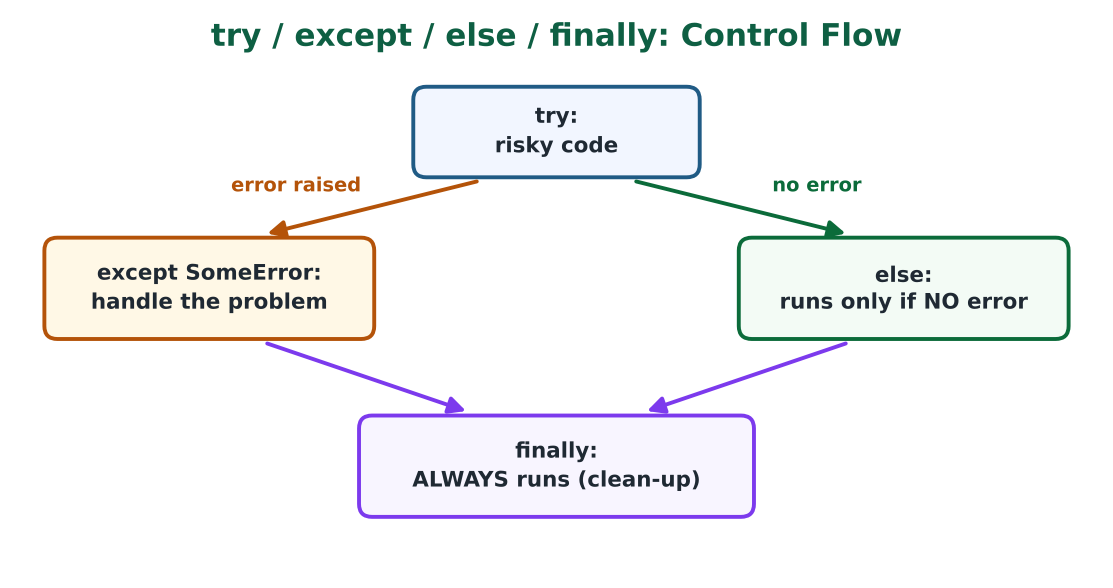</div>

## `try` / `except`

Put risky code in a `try` block. If an exception occurs, Python jumps to a matching `except` block instead of crashing.

In [ ]:
def safe_divide(a_text, b_text):
    try:
        a = int(a_text)
        b = int(b_text)
        print(f"{a} / {b} = {a / b:.2f}")
    except ValueError:
        print(f"  Could not convert {a_text!r} or {b_text!r} to a number.")
    except ZeroDivisionError:
        print("  Cannot divide by zero.")


safe_divide("10", "4")
safe_divide("ten", "4")
safe_divide("10", "0")

<div class="warning">
<b>Be specific!</b> A bare <code>except:</code> (or <code>except Exception:</code> that just does <code>pass</code>) hides real bugs and gives the user no warning. Catch the specific exceptions you expect and know how to handle.
</div>

## `else` and `finally`

- `else:` runs only if the `try` block finished with **no** exception.
- `finally:` **always** runs, whether or not there was an error. It is ideal for clean-up.

In [ ]:
def read_first_line(path):
    try:
        with open(path, encoding="utf-8") as f:
            first = f.readline().strip()
    except FileNotFoundError:
        print(f"  File not found: {path}")
        return None
    except PermissionError:
        print(f"  No permission to read: {path}")
        return None
    else:
        print("  Read succeeded.")
        return first
    finally:
        print("  (finally: this line always runs)")


print(read_first_line(RAVEN))
print(read_first_line(DATA_DIR / "missing.txt"))

## A File-Specific Example: Ask Forgiveness, Not Permission

You can check first (`if os.path.exists(...)`) or just try and handle the failure. In Python, the second style is common because the file could be deleted between the check and the open.

In [ ]:
# Style 1: look before you leap
if os.path.exists(DATA_DIR / "maybe.txt"):
    print("Found it")
else:
    print("Style 1: file is missing")

# Style 2: try, then handle the failure
try:
    with open(DATA_DIR / "maybe.txt", encoding="utf-8") as f:
        print(f.read())
except FileNotFoundError:
    print("Style 2: file is missing")

In [ ]:
# "x" mode refuses to overwrite: great for protecting results
target = DATA_DIR / "write_demo.txt"          # this file already exists
try:
    with open(target, "x", encoding="utf-8") as f:
        f.write("This will not be written")
except FileExistsError as error:
    print("Protected by 'x' mode:", error)

# Invalid JSON (single quotes) also raises a specific exception
try:
    json.loads("{'name': 'Alice'}")
except json.JSONDecodeError as error:
    print("Not valid JSON:", error)

## What Should a Function Do When It Cannot Do Its Job?

Suppose we compute class averages, and one student has **no grades**. Dividing by `len([])` raises `ZeroDivisionError`. There are several possible policies:

| Policy | How | Problem |
|---|---|---|
| Fail silently | Return a default and say nothing | The user gets wrong numbers with no warning (**bad idea**) |
| Return a special value | Return `None` or `-1` | Every caller must remember to check it |
| Change the policy | Decide "no grades = 0.0" and document it | Fine if it is a deliberate, documented rule |
| **Raise an exception** | `raise ValueError("...")` | The problem cannot be ignored (**usually best**) |

In [ ]:
grades_by_student = {"Alice": [90, 85, 100], "Bob": [70, 75], "Cara": []}     # Cara has no grades


def average_returns_none(grades):
    try:
        return sum(grades) / len(grades)
    except ZeroDivisionError:
        print("  warning: no grades data")        # prints, then silently returns None


def average_default_zero(grades):
    try:
        return sum(grades) / len(grades)
    except ZeroDivisionError:
        print("  warning: no grades data, using 0.0")
        return 0.0


for name, grades in grades_by_student.items():
    print(name, "->", average_returns_none(grades))
print()
for name, grades in grades_by_student.items():
    print(name, "->", average_default_zero(grades))

## `raise` and `assert`: Defensive Programming

- **`raise`** stops the function with an exception **you** choose. Use it when **users or other code** may supply bad input.
- **`assert condition, message`** raises `AssertionError` if the condition is `False`. Use it to check **your own assumptions** while developing.

<div class="warning">
<b>Do not use <code>assert</code> to validate user input.</b> Assertions can be switched off (<code>python -O</code>), and then the check disappears. Use <code>raise</code> for input validation.
</div>

In [ ]:
def average_assert(grades):
    assert len(grades) != 0, "no grades data"       # a sanity check for the programmer
    return sum(grades) / len(grades)


def average(scores):
    """Return the mean of a non-empty list of numbers. Raise ValueError if empty."""
    if len(scores) == 0:
        raise ValueError("average() needs at least one score")
    return sum(scores) / len(scores)


for func in (average_assert, average):
    try:
        func([])
    except (AssertionError, ValueError) as error:
        print(f"{func.__name__:15} raised {type(error).__name__}: {error}")

print("average([80, 90, 100]) =", average([80, 90, 100]))

<div class="checkpoint">
<b>Checkpoint:</b> You are writing a function that reads a file chosen by a user. Which should you use to deal with a missing file: <code>assert</code>, <code>raise</code>, or <code>try/except</code>? What about a function that should never receive a negative length because <i>your own</i> earlier code guarantees it?
</div>

# Part 8. Mini Project: A Class Gradebook Pipeline

Let's combine files, CSV, JSON, and exceptions in one small, realistic program: **read** a CSV of scores, **compute** averages, **write** a text report, and **save** a JSON summary. We build it from small functions, because small functions are easy to test (Part 9 and Part 11).

In [ ]:
def load_students(path):
    """Read a CSV with columns name, major, exam1, exam2, project.

    Returns a list of dicts: {"name": str, "major": str, "scores": [int, int, int]}.
    Raises FileNotFoundError if the file does not exist.
    """
    students = []
    with open(path, newline="", encoding="utf-8") as f:
        for row in csv.DictReader(f):
            students.append({
                "name": row["name"],
                "major": row["major"],
                "scores": [int(row["exam1"]), int(row["exam2"]), int(row["project"])],
            })
    return students


def write_report(students, path):
    """Write one line per student with the average score."""
    with open(path, "w", encoding="utf-8") as f:
        f.write("Class Report\n")
        f.write("============\n")
        for s in students:
            f.write(f"{s['name']:<10} {s['major']:<20} average = {average(s['scores']):6.2f}\n")


def save_summary(students, path):
    """Save the class mean and the top student as JSON. Returns the summary dict."""
    averages = {s["name"]: average(s["scores"]) for s in students}
    top = max(averages, key=averages.get)
    summary = {
        "students": len(students),
        "class_mean": round(sum(averages.values()) / len(averages), 2),
        "top_student": top,
        "top_average": round(averages[top], 2),
    }
    with open(path, "w", encoding="utf-8") as f:
        json.dump(summary, f, indent=4)
    return summary

In [ ]:
def run_pipeline(csv_path, out_dir):
    """Run the whole pipeline. Return the summary, or None if the input file is missing."""
    out_dir = Path(out_dir)
    try:
        students = load_students(csv_path)
    except FileNotFoundError:
        print(f"Cannot find the input file: {csv_path}")
        return None
    write_report(students, out_dir / "class_report.txt")
    return save_summary(students, out_dir / "class_summary.json")


summary = run_pipeline(CSV_PATH, DATA_DIR)
print("Summary:", summary)
print()
print((DATA_DIR / "class_report.txt").read_text(encoding="utf-8"))
print("Missing input ->", run_pipeline(DATA_DIR / "nope.csv", DATA_DIR))

<div class="checkpoint">
<b>Checkpoint:</b> Which lines of this pipeline would break if a CSV row had a blank score? Where would you add error handling? Keep this question in mind. You will test exactly this kind of case soon.
</div>

# Part 9. Testing Fundamentals: Is My Code Correct?

**Reading:** MIT 6.0001 Lecture 7: Testing, Debugging, Exceptions, Assertions (see sources)

Running a program once and seeing plausible output does **not** show that it is correct. The next five parts form a **testing track**. Each part answers one question and builds on the one before it:

| Part | Question it answers | You will be able to... |
|---|---|---|
| **9. Fundamentals** | *What is a test, and what do I compare against?* | Write a specification, a test case, and a simple hand-made test |
| **10. Designing test cases** | *Which inputs should I test?* | Choose typical, **boundary**, invalid, and empty cases using black-box and glass-box thinking |
| **11. Debugging** | *A test failed. Now what?* | Follow a step-by-step workflow to find and fix the bug |
| **12. Automated testing with pytest** | *How do I run hundreds of tests in one second?* | Write and run a pytest test suite |
| **13. Testing and GenAI** | *Can I trust code that an AI wrote?* | Use tests to check, and improve, AI-generated code |

<div class="callout">
<b>The big picture:</b> <b>Specify</b> what the function should do → <b>design</b> test cases → <b>run</b> them → if one fails, <b>debug</b> → <b>fix</b> → run <b>all</b> tests again.
</div>

## 9.1 Why Do We Test? The Soup Analogy

Imagine making soup while bugs keep falling in from the ceiling. What can you do?

| Soup strategy | Programming strategy | Where we learn it |
|---|---|---|
| **Check the soup** for bugs | **Testing:** compare actual results with expected results | Parts 9, 10, 12 |
| **Keep the lid closed** | **Defensive programming:** specifications, input checks, `assert`, `raise` | Part 7 and Part 9 |
| **Clean the kitchen** | **Eliminate the source of bugs:** small functions, clear design, good habits | Throughout |

<div class="figure">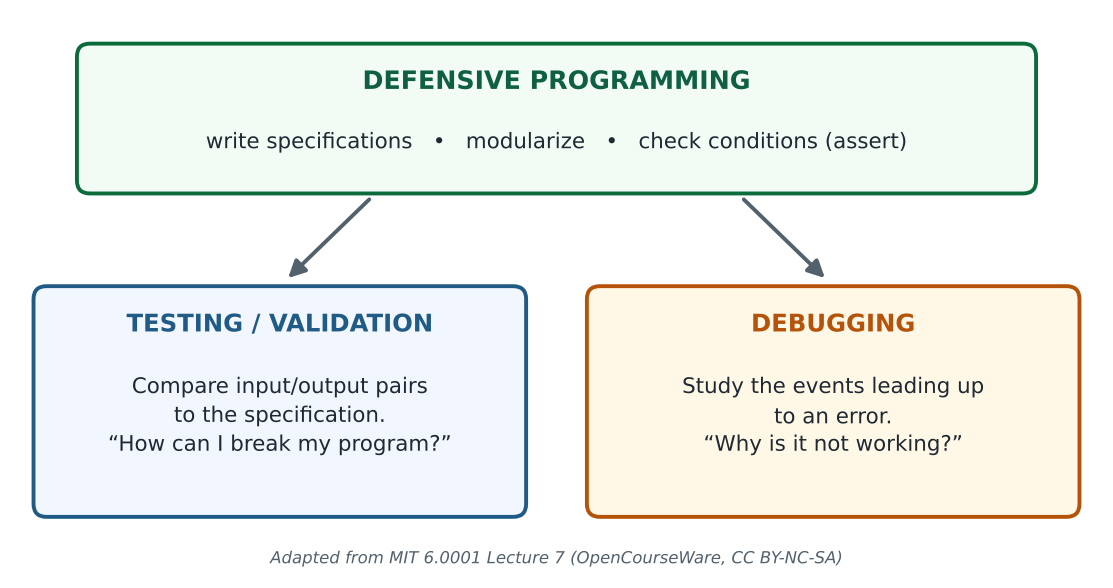</div>

## 9.2 Key Vocabulary

Learn these words now. We use them in every part that follows.

| Term | Meaning | Example |
|---|---|---|
| **Bug** | A mistake in the code that makes it behave differently from what we intended | `x < -1` instead of `x < 0` |
| **Specification** | A precise description of what a function **assumes** and what it **returns** | The docstring of `letter_grade` |
| **Test case** | One **input** together with the **expected output** | `letter_grade(90)` should give `"A"` |
| **Actual output** | What the code really returns when we run it | `"B"` (if the code has a bug) |
| **Pass / Fail** | Pass: actual equals expected. Fail: they differ | |
| **Test suite** | A collection of test cases that we can run together | All tests for the gradebook |
| **Unit** | The smallest testable piece, usually **one function** | `average()` |

<div class="callout">
<b>Golden rule:</b> The <b>expected</b> output must come from the <b>specification</b> (or from a calculation you did independently), <b>never</b> from running your own code and copying whatever it printed. Otherwise your test can only confirm the bug.
</div>

## 9.3 Start with a Specification

You cannot test a function until you know what it is *supposed* to do. A good docstring answers three questions:

| Question | Docstring keyword | Example for `average(scores)` |
|---|---|---|
| What must be true about the **inputs**? | **Assumes** | `scores` is a list of numbers |
| What does it **return**? | **Returns** | The mean of the scores |
| What happens in a **bad** situation? | **Raises** | `ValueError` if the list is empty |

Here is `average` written with a full specification. Notice that the specification already hints at test cases: a normal list, a one-item list, and an empty list.

In [ ]:
def average(scores):
    """Return the mean of a list of numbers.

    Assumes: scores is a list of ints or floats.
    Returns: sum(scores) / len(scores).
    Raises:  ValueError if scores is empty.
    """
    if len(scores) == 0:
        raise ValueError("average() needs at least one score")
    return sum(scores) / len(scores)


help(average)       # Python shows the docstring: the specification is also documentation

<div class="checkpoint">
<b>Checkpoint:</b> Write a docstring (Assumes / Returns / Raises) for <code>count_lines_and_words(path)</code> from Part 4. What should it do if the file does not exist?
</div>

## 9.4 From "Looks OK" to Automatic Checking: Four Levels of Testing

Test quality improves in four steps. Levels 1–3 are done by hand in this part; Level 4 (pytest) is Part 12.

### Level 1: Print and eyeball

Quick, but **you** must remember the right answer and compare it yourself, every time.

In [ ]:
print("average([80, 90, 100]) ->", average([80, 90, 100]))      # is 90.0 right? you must check
print("average([70])          ->", average([70]))

### Level 2: `assert` (silent when correct, loud when wrong)

`assert condition` does nothing if the condition is `True`, and raises `AssertionError` if it is `False`. The **expected value is written into the code**, so the computer does the comparing.

In [ ]:
assert average([80, 90, 100]) == 90
assert average([70]) == 70
print("All assertions passed (silence means success).")

In [ ]:
# What does a failing assertion look like?  (We catch it so the notebook keeps running.)
try:
    assert average([1, 2]) == 2, "expected 2, but average([1, 2]) returned something else"
except AssertionError as error:
    print("AssertionError:", error)
print("Actual value was:", average([1, 2]))

<div class="warning">
<b>Think!</b> A failing test means <b>either</b> the code <b>or</b> the expected value is wrong. Here the code is right: the mean of 1 and 2 is 1.5, so our <i>expectation</i> was the mistake. <b>The specification decides who is right.</b>
</div>

### Level 3: A table of test cases and a PASS/FAIL report

Many `assert` lines get repetitive, and the first failure stops everything. A **test table** (a list of `(input, expected)` pairs) plus a small loop runs *all* cases and reports each one. We reuse this helper throughout the testing track.

In [ ]:
def run_cases(func, cases):
    """Run func(arg) for each (arg, expected) pair. Print PASS/FAIL lines. Return the number of failures."""
    failures = 0
    for arg, expected in cases:
        actual = func(arg)
        ok = (actual == expected)
        failures += (not ok)
        print(f"{'PASS' if ok else 'FAIL'}  {func.__name__}({arg!r}) -> {actual!r}   (expected {expected!r})")
    print(f"--> {len(cases) - failures} of {len(cases)} passed\n")
    return failures


average_cases = [
    ([80, 90, 100], 90),        # typical
    ([70], 70),                 # boundary: a single item
    ([0, 100], 50),             # extremes of the score range
    ([-10, 10], 0),             # negative numbers cancel out
]
run_cases(average, average_cases)

**Level 4** is pytest: the same idea, but with automatic discovery, clear failure reports, and many extra tools (Part 12).

## 9.5 When Are You Ready to Test?

1. The code **runs**: no syntax errors (Python finds these for you when you run the cell).
2. You have a **set of expected results**: some inputs, and for each one the output you expect **from the specification**.

## 9.6 Three Kinds of Tests: Unit, Regression, Integration

Different tests answer different questions. Here they are, with examples from **our own gradebook code**:

| Type | Question it answers | Typical size | Our example |
|---|---|---|---|
| **Unit test** | Does *this one function* work by itself? | One function, runs in milliseconds | `letter_grade(90) == "A"` |
| **Regression test** | Did a bug we **already fixed** come back? | One test per bug you found | `my_abs(-1) == 1` |
| **Integration test** | Do the pieces work **together** as a whole program? | Several functions, files, or modules | Run the whole pipeline on a small CSV |

Write **many** unit tests (fast, and a failure points straight at the broken function) and **fewer** integration tests. Add a regression test **every time** you fix a bug.

Here is a small **integration test**, written by hand: run the whole gradebook pipeline on a tiny CSV and check the results.

In [ ]:
it_dir = DATA_DIR / "integration"
it_dir.mkdir(exist_ok=True)
(it_dir / "mini.csv").write_text(
    "name,major,exam1,exam2,project\n"
    "Ann,Data Science,100,100,100\n"
    "Ben,Data Science,50,60,70\n",
    encoding="utf-8",
)

result = run_pipeline(it_dir / "mini.csv", it_dir)       # runs load -> report -> summary together

assert result["students"] == 2
assert result["top_student"] == "Ann"
assert result["class_mean"] == 80.0                      # (100 + 60) / 2, calculated by hand
assert (it_dir / "class_report.txt").exists()
assert (it_dir / "class_summary.json").exists()
print("Integration check passed:", result)

# Part 10. Designing Good Test Cases

Testing can never **prove** a program has no bugs. It can only **find** bugs, so the goal is to choose test cases that are *most likely to expose a bug*. A test suite of ten random inputs is much weaker than a suite of ten carefully chosen ones.

## 10.1 A Four-Step Recipe

| Step | What to do | Example for `letter_grade(score)` |
|---|---|---|
| **1. Read the specification** | Find every rule, limit, and error condition | Five grade bands, valid range 0–100, `ValueError` outside |
| **2. Split the inputs into groups** | Inputs in the same group should behave the same way | F, D, C, B, A, plus "too low" and "too high" |
| **3. Pick test values** | One **typical** value per group **and** the **boundaries** between groups | 75 (typical C), 70 and 69.99 (boundary) |
| **4. Write the expected result first** | From the specification, *before* running the code | `letter_grade(70)` should be `"C"` |

Throughout Part 10 and Part 12 we test this function. Read its **specification** (the docstring) carefully: it is where our expected results come from.

In [ ]:
def letter_grade(score):
    """Return 'A', 'B', 'C', 'D' or 'F' for a score from 0 to 100 (inclusive).

    A: 90 or more, B: 80 to 89.99, C: 70 to 79.99, D: 60 to 69.99, F: below 60.
    Raise ValueError if the score is outside 0..100.
    """
    if not 0 <= score <= 100:
        raise ValueError(f"score must be between 0 and 100, got {score}")
    if score >= 90:
        return "A"
    elif score >= 80:
        return "B"
    elif score >= 70:
        return "C"
    elif score >= 60:
        return "D"
    return "F"

## 10.2 Categories of Test Cases

Whatever the function does, ask yourself whether you have a test from **each** category:

| Category | Meaning | Numbers | Lists / strings | Files |
|---|---|---|---|---|
| **Typical** | Normal, expected use | `85` | `[80, 90, 100]` | A normal data file |
| **Boundary** | On or next to a limit | `90`, `89.99`, `0`, `100` | One item; two items | One line only |
| **Empty / minimal** | Nothing at all | `0` | `[]`, `""` | An empty file |
| **Invalid** | Should be rejected | `-1`, `101` | Wrong type, `None` | Missing file, bad format |
| **Special** | Unusual but legal | Negative numbers, huge numbers | Duplicates, extra spaces, non-ASCII text | Blank lines, no final new line |

## 10.3 Black-Box Testing: Test from the Specification

**Black-box testing** designs tests **without looking at the code**, using only the specification. Advantages: it can be written by someone other than the author (avoiding the author's blind spots), and the tests are **reused** when the code is rewritten.

Our partition of `letter_grade`'s inputs looks like this. Each coloured box is one **group**; the green triangles are **boundary** values.

<div class="figure">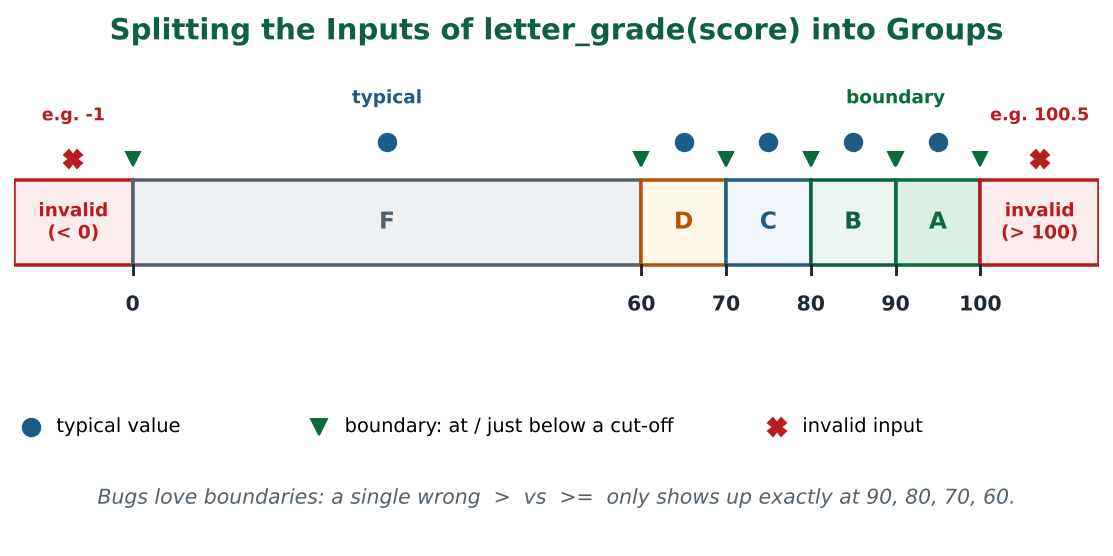</div>

### Why Do Boundaries Matter So Much?

A classic bug is the **off-by-one** mistake: writing `>` where the specification needs `>=`. Watch what happens when we test a buggy version with **typical values only**, then with **boundary values**.

In [ ]:
def letter_grade_buggy(score):
    """Same specification as letter_grade, but with a classic mistake: > instead of >=."""
    if not 0 <= score <= 100:
        raise ValueError(f"score must be between 0 and 100, got {score}")
    if score > 90:        # BUG: a score of exactly 90 should be an A
        return "A"
    elif score > 80:
        return "B"
    elif score > 70:
        return "C"
    elif score > 60:
        return "D"
    return "F"


typical_cases  = [(95, "A"), (85, "B"), (75, "C"), (65, "D"), (30, "F")]
boundary_cases = [(90, "A"), (80, "B"), (70, "C"), (60, "D"), (100, "A"), (0, "F")]

print("=== Typical values only ===")
run_cases(letter_grade_buggy, typical_cases)
print("=== Boundary values ===")
run_cases(letter_grade_buggy, boundary_cases)

<div class="callout">
<b>Lesson:</b> All five typical cases passed, so the bug was invisible. Only the <b>boundary</b> cases (90, 80, 70, 60) exposed it. Always test the edges of every group.
</div>

Now the correct function, tested with a complete black-box table (typical + boundary + just-below-boundary):

In [ ]:
letter_grade_cases = [
    (100, "A"), (95, "A"), (90, "A"),                 # A group
    (89.99, "B"), (85, "B"), (80, "B"),               # B group
    (79.99, "C"), (75, "C"), (70, "C"),               # C group
    (69.99, "D"), (65, "D"), (60, "D"),               # D group
    (59.99, "F"), (30, "F"), (0, "F"),                # F group
]
run_cases(letter_grade, letter_grade_cases)

In [ ]:
# Invalid inputs must raise ValueError (testing the "Raises" part of the specification)
for bad in (-1, 100.5, 250):
    try:
        letter_grade(bad)
        print(f"FAIL  letter_grade({bad}) did not raise an error")
    except ValueError:
        print(f"PASS  letter_grade({bad}) raised ValueError")

## 10.4 Testing Functions That Use Lists, Strings, and Files

The same recipe works for any function. For `count_lines_and_words(path)`, the "typical, boundary, empty, special" categories translate into **file contents**:

| Category | File content | Expected `(lines, words)` |
|---|---|---|
| Empty | `""` | `(0, 0)` |
| Minimal | `"hello\n"` | `(1, 1)` |
| No final new line | `"hello"` | `(1, 1)` |
| Blank line in the middle | `"one two\n\nthree\n"` | `(3, 3)` |
| Extra spaces | `"  spaced   out  \n"` | `(1, 2)` |
| Non-ASCII text | `"naïve café\n"` | `(1, 2)` |

Tests for file code need real files. We create a **temporary** folder so that tests never touch our real data. (pytest does this for us with `tmp_path`, as you will see in Part 12.)

In [ ]:
import tempfile

file_cases = [
    ("",                     (0, 0)),     # empty file
    ("hello\n",              (1, 1)),     # minimal
    ("hello",                (1, 1)),     # no final new line
    ("one two\n\nthree\n",   (3, 3)),     # blank line still counts as a line
    ("  spaced   out  \n",   (1, 2)),     # extra spaces
    ("naïve café\n",         (1, 2)),     # non-ASCII characters
]

with tempfile.TemporaryDirectory() as folder:           # deleted automatically afterwards
    case_file = Path(folder) / "case.txt"
    for text, expected in file_cases:
        case_file.write_text(text, encoding="utf-8")
        actual = count_lines_and_words(case_file)
        status = "PASS" if actual == expected else "FAIL"
        print(f"{status}  content={text!r:22} -> {actual}   (expected {expected})")

## 10.5 Glass-Box Testing: Test from the Code

**Glass-box testing** (also called white-box) designs tests by **looking at the code**, so that every part of it is executed at least once. Use these guidelines:

| Code structure | Cases to include |
|---|---|
| `if` / `elif` / `else` | **Every branch** gets at least one test |
| `for` loop | Loop **not entered** (empty), body runs **exactly once**, body runs **more than once** |
| `while` loop | The same as `for`, plus a test for **every way to exit** the loop |
| `try` / `except` | A test where **no** error happens, and one for **each** `except` |

Example: this function has a loop and an `if`. Which test cases cover every structure?

In [ ]:
def count_positive(values):
    """Return how many numbers in values are greater than 0."""
    count = 0
    for v in values:
        if v > 0:
            count += 1
    return count


glass_cases = [
    ([],              0),     # loop never entered
    ([5],             1),     # loop once, if-branch taken
    ([-5],            0),     # loop once, if-branch NOT taken
    ([3, -1, 7, 0],   2),     # loop many times, both branches, and the boundary 0
]
run_cases(count_positive, glass_cases)

### A glass-box suite can still miss a bug

This `my_abs` has a mistake. A test suite that covers **both branches** (`2` and `-2`) passes, yet the function is wrong. **Boundary testing finds the bug.**

In [ ]:
def my_abs(x):
    """Return the absolute value of an integer x."""
    if x < -1:                 # BUG: should be x < 0
        return -x
    else:
        return x


print("Path-complete tests (both branches):")
for x in (2, -2):
    print(f"  my_abs({x}) = {my_abs(x)}   correct: {my_abs(x) == abs(x)}")

print("Boundary tests:")
for x in (-1, 0, 1):
    print(f"  my_abs({x}) = {my_abs(x)}   correct: {my_abs(x) == abs(x)}")

<div class="checkpoint">
<b>Your turn:</b> Fix <code>my_abs</code> in the cell above (change <code>x &lt; -1</code> to <code>x &lt; 0</code>) and run both cells again. Keep <code>my_abs(-1)</code> as a permanent <b>regression test</b>.
</div>

## 10.6 Black Box vs. Glass Box: Use Both

| | Black-box testing | Glass-box testing |
|---|---|---|
| **Designed from** | The specification | The source code |
| **Needs the code?** | No | Yes |
| **Finds** | Missing features, wrong results, boundary mistakes | Untested branches and loops, dead code |
| **Weakness** | May not exercise every path through the code | A *complete* set of paths can still miss a boundary bug |
| **Reusable after a rewrite?** | **Yes** | No: it depends on how the code is written |

**Practical advice:** start with black-box tests from the specification, then look at the code and add glass-box tests for any branch or loop you have not exercised.

## 10.7 Regression Tests: Every Bug Becomes a Test

When you find a bug:

1. **Write a test that fails** because of the bug (it proves you understand the bug).
2. **Fix** the code.
3. Run the test again: it **passes**.
4. **Keep the test forever.** If someone (or an AI tool) later reintroduces the bug, the test fails immediately.

We will practice this loop in Part 11.

## 10.8 Try It: Design the Tests Yourself

**Specification:**

```python
def is_valid_password(password):
    """Return True if password has at least 8 characters,
    at least one digit, and contains no spaces. Otherwise return False."""
```

On paper (or in the cell below), list **at least six** test cases with expected results. Think: *typical, boundary (length 7 and 8), empty, and special*. Then reveal our suggested table.

In [ ]:
# Write your own test table here as a list of (password, expected) pairs
my_password_cases = [
    # ("example1", True),
]

<details>
<summary><b>Click to reveal a suggested test table</b></summary>

| Password | Expected | Why this case? |
|---|---|---|
| `"abcdefg1"` | `True` | **Boundary:** exactly 8 characters, one digit |
| `"abcdef1"` | `False` | **Boundary:** 7 characters (one too short) |
| `"12345678"` | `True` | Only digits is fine |
| `"abcdefgh"` | `False` | Long enough but **no digit** |
| `"abcd efg1"` | `False` | Contains a **space** |
| `""` | `False` | **Empty** string |
| `"Passw0rd!"` | `True` | **Typical** valid password |

</details>

Now implement the function and run our table. Did your table catch the same boundaries?

In [ ]:
def is_valid_password(password):
    """Return True if password has at least 8 characters, at least one digit, and no spaces."""
    return len(password) >= 8 and any(ch.isdigit() for ch in password) and " " not in password


password_cases = [
    ("abcdefg1", True), ("abcdef1", False), ("12345678", True), ("abcdefgh", False),
    ("abcd efg1", False), ("", False), ("Passw0rd!", True),
]
run_cases(is_valid_password, password_cases)

# Part 11. Debugging: From a Failing Test to a Fixed Bug

**Testing** asks: *"Is it working?"* **Debugging** asks: *"Why is it not working, and how do I fix it?"* Debugging has a steep learning curve, but it becomes much easier if you follow a **method** instead of guessing.

## 11.1 Three Kinds of Errors

| Kind | When Python notices | Example | How hard? |
|---|---|---|---|
| **Syntax error** | Before the program runs | `print("hi"` (missing parenthesis) | Easy: Python shows the line |
| **Runtime error (exception)** | While running | `int("abc")`, `[1,2][5]` | Medium: read the traceback |
| **Logic error** | **Never.** Python happily runs it | Wrong formula, `>` instead of `>=` | **Hard:** no error message, just a wrong answer |

Tests are our main weapon against **logic errors**, because Python will not report them.

## 11.2 How to Read a Traceback

When an exception stops your program, Python prints a **traceback**. Read it **from the bottom up**:

```text
Traceback (most recent call last):
  File "<cell>", line 13, in <module>        <- 3. WHO CALLED IT: where the chain started
    print(total_hours(study_log))
  File "<cell>", line 5, in total_hours      <- 2. WHERE: the exact line that failed
    total += hours
TypeError: unsupported operand type(s) for +=: 'int' and 'str'    <- 1. WHAT: read this line FIRST
```

1. **Last line:** the exception type (`TypeError`) and the message. What kind of problem is it?
2. **The line above it:** the exact line of code that failed.
3. **Lines further up:** the chain of function calls that led there.

<div class="figure">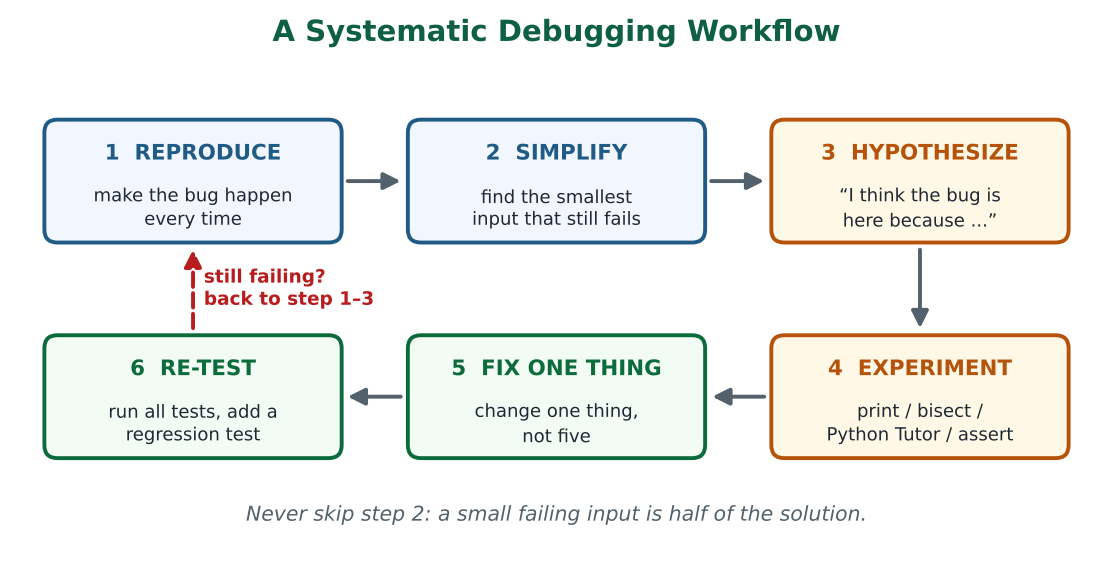</div>

## 11.3 The Debugging Workflow

| Step | What to do | Why |
|---|---|---|
| **1. Reproduce** | Make the bug happen every time | You cannot fix what you cannot repeat |
| **2. Simplify** | Find the **smallest input** that still fails | Less code and data to think about |
| **3. Hypothesize** | Form a guess: *"I think X is wrong because Y"* | Replaces random changes with a **scientific method** |
| **4. Experiment** | Test the guess with `print`, `assert`, bisection, or Python Tutor | Turns a guess into evidence |
| **5. Fix one thing** | Change **one** thing at a time | You know which change mattered |
| **6. Re-test** | Run **all** tests; add a **regression test** | Make sure you fixed it and broke nothing else |

<div class="callout">
<b>Ask the right question.</b> Don't ask "What is wrong with my code?" Ask: <b>"How did I get this unexpected result?"</b> Then trace the values backwards from the wrong output.
</div>

## 11.4 Debugging Tools and Techniques

| Technique | How | Best for |
|---|---|---|
| **Print debugging** | Print *entering function*, *parameters*, and *results*. Use `repr()` to see hidden spaces and `\n` | A quick look at actual values |
| **Bisection** | Put a `print` **halfway** through the code. Wrong already? The bug is in the first half. Correct? It is in the second half. Repeat | Long functions or pipelines |
| **`assert` as a tripwire** | Assert what you *believe* is true at a point in the code | Stopping at the **first** wrong value instead of the last |
| **Python Tutor** | Visualizes every step and variable at [pythontutor.com](https://pythontutor.com/) | Loops, lists, and understanding flow |
| **Rubber-duck debugging** | Explain the code, line by line, to a person or a rubber duck | Logic errors: you often spot it while explaining |
| **Take a break** | Step away | A fresh mind finds bugs faster |

| Don't | Do |
|---|---|
| Write, test, and debug the **entire** program at once | Write a function, test it, debug it; repeat. Then do **integration testing** |
| Change code, "remember" where the bug was, and forget what you changed | **Back up** (or use Git), write the suspected bug in a **comment**, change one thing, test, compare |
| Panic | Follow the workflow above |

## 11.5 Case 1: A Runtime Error (TypeError) from a File

The function below should add up the hours in a study log, but it crashes. **Step 1: reproduce.**

In [ ]:
def total_hours(lines):
    total = 0
    for line in lines:
        name, hours = line.split(",")
        total += hours
    return total


study_log = ["Alice,3", "Bob,5", "Carmen,4"]

import traceback
try:
    print(total_hours(study_log))
except TypeError:
    traceback.print_exc()       # prints the traceback so we can read it, without stopping the notebook

**Step 2: read the traceback.** The last line says we cannot add a `str` to an `int` (`+=` on line 5). **Step 3: hypothesis.** `line.split(",")` returns **strings**, so `hours` is `"3"`, not `3`. **Step 4: experiment.** Print the type to test the hypothesis:

In [ ]:
def total_hours(lines):
    total = 0
    for line in lines:
        name, hours = line.split(",")
        print("DEBUG:", repr(name), repr(hours), type(hours))     # temporary experiment!
        total += int(hours)                                      # Step 5: the fix
    return total


print(total_hours(study_log))

The experiment confirmed the hypothesis. **Step 6: clean up and re-test.** Remove the debug `print`, and keep a **regression test** so this bug can never come back.

In [ ]:
def total_hours(lines):
    """Return the total hours from lines like 'Alice,3'. Hours must be whole numbers."""
    total = 0
    for line in lines:
        name, hours = line.split(",")
        total += int(hours)
    return total


# Regression tests for the bug we just fixed
assert total_hours(["Alice,3", "Bob,5", "Carmen,4"]) == 12
assert total_hours([]) == 0
print("Regression tests passed.")

## 11.6 Case 2: A Logic Error (Wrong Answer, No Error Message)

Logic errors give no error message, which makes them harder. **Reproduce first:**

In [ ]:
def find_max(values):
    best = 0
    for v in values:
        if v > best:
            best = v
    return best


print(find_max([3, 9, 4]))        # expected 9
print(find_max([-5, -2, -9]))     # expected -2

**Step 2: simplify.** What is the *smallest* input that still fails? Try `find_max([-1])`. **Step 3: hypothesis.** Which line decides the starting value? Can it be larger than every number in the list?

<div class="checkpoint">
<b>Your turn:</b> (a) State your hypothesis in one sentence. (b) Fix <code>find_max</code> in the cell above. (c) Decide what it should do for an <i>empty</i> list. Then run the test table below. If you have not fixed the function yet, the table will show you exactly which cases fail.
</div>

In [ ]:
find_max_cases = [
    ([3, 9, 4], 9),          # typical
    ([-5, -2, -9], -2),      # all negative  <- exposes the bug
    ([7], 7),                # one item
    ([-1], -1),              # one negative item (the simplest failing input)
    ([2, 2], 2),             # duplicates
]
run_cases(find_max, find_max_cases)

<details>
<summary><b>Click to reveal one possible fix</b></summary>

**Hypothesis:** the starting value `best = 0` is larger than every number in an all-negative list, so `v > best` is never true. **Fix:** start from the first element, and decide what to do with an empty list (we raise `ValueError`, just like `average`).

```python
def find_max(values):
    """Return the largest number in a non-empty list. Raise ValueError if empty."""
    if len(values) == 0:
        raise ValueError("find_max() needs at least one value")
    best = values[0]
    for v in values[1:]:
        if v > best:
            best = v
    return best
```

</details>

## 11.7 Case 3: Finding a Bug by Bisection

Here is a pipeline of several small steps. It should clean raw text lines and return the average of the valid scores (0 to 100, inclusive). It returns the wrong answer. Instead of staring at everything, we **bisect**.

In [ ]:
def summarize_scores(lines):
    """Return the mean of the valid scores (whole numbers from 0 to 100, inclusive)."""
    cleaned = [line.strip() for line in lines]                 # stage 1
    nonblank = [line for line in cleaned if line]              # stage 2
    numbers = [int(x) for x in nonblank if x.isdigit()]        # stage 3
    valid = [n for n in numbers if 0 <= n < 100]               # stage 4
    return sum(valid) / len(valid)                             # stage 5


raw = [" 90 ", "", "100", "abc", "75", "80\n"]
print("Result  :", round(summarize_scores(raw), 2))
print("Expected:", (90 + 100 + 75 + 80) / 4)                   # calculated by hand: 86.25

**Bisect:** the result is wrong. Print the values **halfway** (after stage 3). If they are already wrong, the bug is in stages 1–3; if they are correct, it is in stages 4–5.

In [ ]:
cleaned = [line.strip() for line in raw]
nonblank = [line for line in cleaned if line]
numbers = [int(x) for x in nonblank if x.isdigit()]
print("after stage 3 (numbers):", numbers)       # [90, 100, 75, 80] -> correct, so stages 1-3 are fine

valid = [n for n in numbers if 0 <= n < 100]
print("after stage 4 (valid)  :", valid)         # [90, 75, 80] -> 100 is missing!

The data is correct after stage 3 and wrong after stage 4, so the bug is in stage 4: `n < 100` should be `n <= 100`. Fix it by editing the function above and re-running both cells. Then add this input to your tests as a **regression test**.

<div class="checkpoint">
<b>Debugging checklist:</b> Did I read the <b>last line</b> of the traceback? Do I have the <b>smallest failing input</b>? Have I written down a <b>hypothesis</b>? Did I change only <b>one thing</b>? Did I run <b>all</b> tests, and add a <b>regression test</b>?
</div>

# Part 12. Automated Testing with pytest

**Reading:** [Introduction to Python Testing — Liam Keegan, SSC](https://ssciwr.github.io/python-testing-intro) | [pytest documentation](https://docs.pytest.org/)

In Part 9 we built `run_cases()` by hand. **pytest** is a professional testing tool that does the same job better: it **finds** your tests automatically, runs them all, and prints a **clear report** when one fails.

## 12.1 Why Automate?

| By hand (Parts 9–11) | With pytest |
|---|---|
| You write the loop and the PASS/FAIL printing | pytest provides it |
| You must remember to run each check | One command runs **every** test |
| A failure shows little detail | A failure shows the **inputs, expected, and actual** values |
| Hard to share or repeat | Tests live in files; anyone can run them, even automatically on every change |

**Benefits of a good test suite:** it confirms code is correct when you write it and **stays correct** as things change; you can change or clean up code **without fear**; you find bugs **earlier**; and the tests double as **documentation** of how the code should be used.

<div class="figure">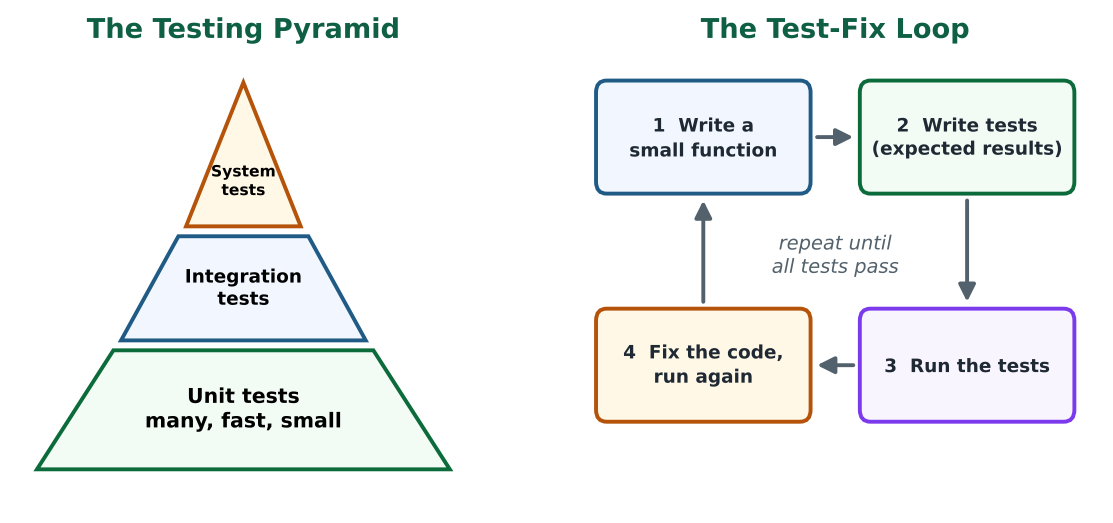<p class="figcap">Most of your tests should be fast unit tests; add fewer integration tests on top.</p></div>

## 12.2 pytest in Five Steps

1. For every file `x.py`, create a file `test_x.py`.
2. Inside it, write functions whose names **start with `test_`**.
3. In each test function, `assert` something about the code in `x.py`.
4. Run `python -m pytest` in the terminal.
5. Read the report. Fix. Repeat.

In **this notebook** we use **ipytest**, which runs pytest tests directly in a cell. The next two cells install and activate it. (If it asks you to restart the kernel after installing, do so, then run the notebook again from the top.)

In [ ]:
%pip install -q pytest ipytest

In [ ]:
import pytest
import ipytest

ipytest.autoconfig()      # lets us use the %%ipytest cell magic
print("pytest", pytest.__version__, "is ready")

<div class="callout">
<b>How to run a test cell:</b> the <b>first line</b> of the cell must be <code>%%ipytest -q</code> (the <code>-q</code> means "quiet", for a shorter report). The functions under test (<code>average</code>, <code>letter_grade</code>, <code>load_students</code>, ...) were defined in earlier cells, so run those cells first.
</div>

## 12.3 Anatomy of a Test: Arrange – Act – Assert

Every good test has the same three parts:

<div class="figure">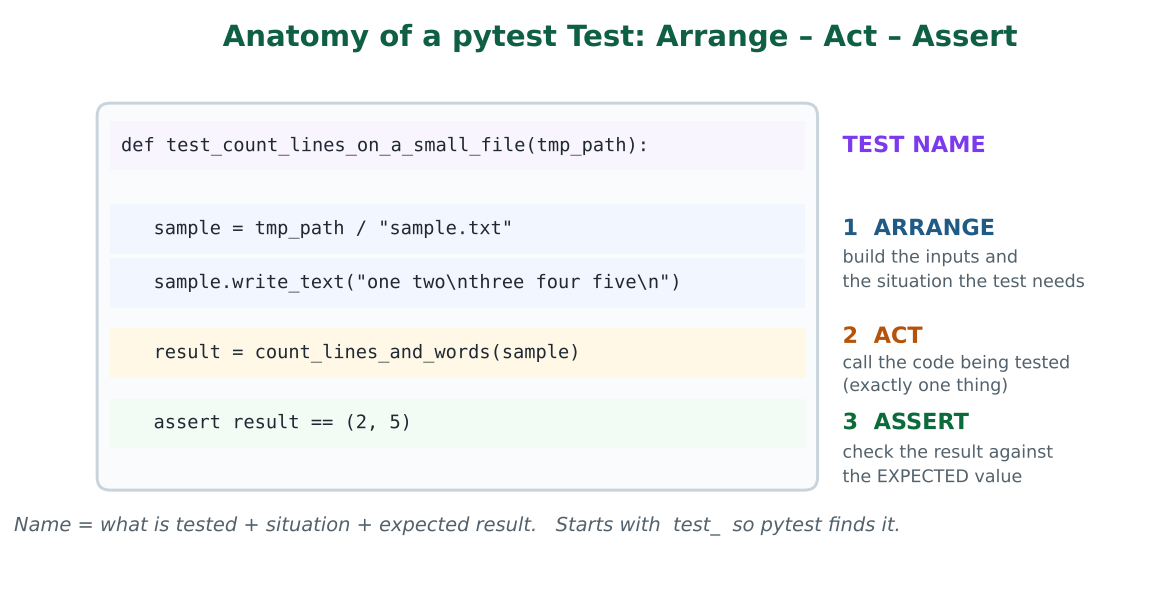</div>

**Naming tests.** The name appears in the failure report, so make it a sentence: `test_<what>_<situation>_should_<result>`.

| Poor name | Better name |
|---|---|
| `test1` | `test_average_of_empty_list_should_raise_value_error` |
| `test_grade` | `test_letter_grade_90_should_be_A` |
| `test_file` | `test_count_lines_and_words_on_an_empty_file_should_be_zero` |

## 12.4 Step 1: Your First Tests

A passing test shows a dot (`.`) and a summary such as `2 passed`.

In [ ]:
%%ipytest -q

def test_letter_grade_90_should_be_A():
    assert letter_grade(90) == "A"


def test_average_of_three_scores_should_be_90():
    assert average([80, 90, 100]) == 90

### What does pytest print when everything passes?

```text
..                                                [100%]
2 passed in 0.01s
```

Each `.` is one passing test. `F` means a failing test. If **no** test is found you see `no tests ran`: the most common reason is a function name that does **not** start with `test_`:

In [ ]:
%%ipytest -q

def check_average_of_two_numbers():          # WRONG: does not start with test_  -> pytest ignores it
    assert average([2, 4]) == 3

## 12.5 Step 2: Floating-Point Numbers with `pytest.approx`

Computers store decimals with limited precision, so `==` on floats can fail in surprising ways. `pytest.approx` compares with a small tolerance.

In [ ]:
print("0.1 + 0.2 == 0.3 ?", 0.1 + 0.2 == 0.3)
print("average([0.1, 0.2]) =", average([0.1, 0.2]), "| equals 0.15 ?", average([0.1, 0.2]) == 0.15)

In [ ]:
%%ipytest -q

def test_average_of_floats_should_be_approximately_correct():
    assert average([0.1, 0.2]) == pytest.approx(0.15)

## 12.6 Step 3: Expecting an Error with `pytest.raises`

Good tests check **failure behaviour** too (the **Raises** line of the specification). `pytest.raises` passes only if the exception **does** happen. Add `match=` to also check the error message.

In [ ]:
%%ipytest -q

def test_average_of_empty_list_should_raise_value_error():
    with pytest.raises(ValueError):
        average([])


def test_average_error_message_should_explain_the_problem():
    with pytest.raises(ValueError, match="at least one"):
        average([])

## 12.7 Step 4: Many Inputs, One Test with `@pytest.mark.parametrize`

Remember our test table in Part 10? `parametrize` turns that **table** into tests: the test function runs **once per row**, and pytest reports every row separately.

```python
@pytest.mark.parametrize("score, expected", [ (100, "A"), (90, "A"), ... ])
def test_letter_grade_boundaries(score, expected):
    assert letter_grade(score) == expected
```

| `parametrize` part | Meaning |
|---|---|
| `"score, expected"` | Names of the parameters (the **columns** of the table) |
| `[(100, "A"), (90, "A"), ...]` | The **rows**: one test case each |
| `def test_...(score, expected)` | The test function receives the values of one row at a time |

In [ ]:
%%ipytest -q

@pytest.mark.parametrize("score, expected", [
    (100, "A"), (90, "A"), (89.99, "B"),
    (80, "B"), (70, "C"), (60, "D"),
    (59.99, "F"), (0, "F"),
])
def test_letter_grade_boundaries(score, expected):
    assert letter_grade(score) == expected


@pytest.mark.parametrize("bad_score", [-1, 100.5, 250])
def test_letter_grade_should_reject_scores_outside_0_to_100(bad_score):
    with pytest.raises(ValueError):
        letter_grade(bad_score)

### Reading a Failure Report

If you did **not** fix `my_abs` in Part 10, the next cell **fails on purpose**. This is how pytest helps you find a bug. A failure report looks like this (abridged):

```text
____ test_my_abs_should_match_builtin_abs[-1] ____

x = -1

    @pytest.mark.parametrize("x", [2, -2, -1, 0, 1])
    def test_my_abs_should_match_builtin_abs(x):
>       assert my_abs(x) == abs(x)
E       assert -1 == 1
E        +  where -1 = my_abs(-1)
E        +  and   1 = abs(-1)

1 failed, 4 passed
```

| Line | What it tells you |
|---|---|
| `test_my_abs_should_match_builtin_abs[-1]` | **Which test and which row** failed (`x = -1`) |
| `>  assert my_abs(x) == abs(x)` | The **line** that failed (marked with `>`) |
| `E  assert -1 == 1` | **Actual** (-1) vs **expected** (1) |
| `1 failed, 4 passed` | The summary: only the boundary row failed |

In [ ]:
%%ipytest -q

@pytest.mark.parametrize("x", [2, -2, -1, 0, 1])
def test_my_abs_should_match_builtin_abs(x):
    assert my_abs(x) == abs(x)

<div class="checkpoint">
<b>Your turn:</b> Fix <code>my_abs</code> (Part 10), re-run its definition cell, then re-run the test cell above. All five rows should now pass. This is the <b>fix → re-test</b> loop from the debugging workflow.
</div>

## 12.8 Step 5: Tests That Use Files with `tmp_path`

Tests must **not** read or change your real data files. pytest gives every test a fresh, empty **temporary folder** through the `tmp_path` fixture, and deletes it afterwards. Just add `tmp_path` as a parameter.

In [ ]:
%%ipytest -q

def test_count_lines_and_words_on_a_small_file(tmp_path):
    sample = tmp_path / "sample.txt"                                   # Arrange
    sample.write_text("one two\nthree four five\n", encoding="utf-8")  # Arrange

    result = count_lines_and_words(sample)                             # Act

    assert result == (2, 5)                                            # Assert


@pytest.mark.parametrize("content, expected", [
    ("",                    (0, 0)),
    ("hello",               (1, 1)),
    ("one two\n\nthree\n",  (3, 3)),
    ("naïve café\n",        (1, 2)),
])
def test_count_lines_and_words_edge_cases(tmp_path, content, expected):
    path = tmp_path / "case.txt"
    path.write_text(content, encoding="utf-8")
    assert count_lines_and_words(path) == expected

## 12.9 Step 6: Reusing Setup with Fixtures

A **fixture** is a function that prepares something many tests need (a data file, a list of students, ...). A test receives the fixture by **naming it as a parameter**. Fixtures can use other fixtures: here `students_csv` uses `tmp_path`.

In [ ]:
%%ipytest -q

@pytest.fixture
def students_csv(tmp_path):
    path = tmp_path / "students.csv"
    path.write_text(
        "name,major,exam1,exam2,project\n"
        "Alice,Data Science,88,92,95\n"
        "Bob,Data Science,75,80,70\n",
        encoding="utf-8",
    )
    return path


def test_load_students_should_read_every_row(students_csv):
    assert len(load_students(students_csv)) == 2


def test_load_students_should_convert_scores_to_numbers(students_csv):
    students = load_students(students_csv)
    assert students[0]["scores"] == [88, 92, 95]


def test_load_students_should_raise_for_a_missing_file(tmp_path):
    with pytest.raises(FileNotFoundError):
        load_students(tmp_path / "nope.csv")

## 12.10 Step 7: Testing the Gradebook Pipeline

Now we test the pieces from Part 8: **unit tests** for `write_report` and `save_summary`, and an **integration test** for the whole `run_pipeline`. We also add the **regression test** for the `total_hours` bug from Part 11.

In [ ]:
%%ipytest -q

@pytest.fixture
def two_student_csv(tmp_path):
    path = tmp_path / "students.csv"
    path.write_text(
        "name,major,exam1,exam2,project\n"
        "Ann,Data Science,100,100,100\n"
        "Ben,Data Science,50,60,70\n",
        encoding="utf-8",
    )
    return path


# ---- unit tests ----
def test_write_report_should_list_every_student(two_student_csv, tmp_path):
    report = tmp_path / "report.txt"
    write_report(load_students(two_student_csv), report)
    text = report.read_text(encoding="utf-8")
    assert "Ann" in text
    assert "Ben" in text


def test_save_summary_should_identify_the_top_student(two_student_csv, tmp_path):
    summary = save_summary(load_students(two_student_csv), tmp_path / "summary.json")
    assert summary["top_student"] == "Ann"
    assert summary["class_mean"] == pytest.approx(80.0)


def test_save_summary_should_write_valid_json(two_student_csv, tmp_path):
    out = tmp_path / "summary.json"
    save_summary(load_students(two_student_csv), out)
    assert json.loads(out.read_text(encoding="utf-8"))["students"] == 2


# ---- integration tests ----
def test_run_pipeline_should_create_both_output_files(two_student_csv, tmp_path):
    run_pipeline(two_student_csv, tmp_path)
    assert (tmp_path / "class_report.txt").exists()
    assert (tmp_path / "class_summary.json").exists()


def test_run_pipeline_should_return_none_for_a_missing_input_file(tmp_path):
    assert run_pipeline(tmp_path / "missing.csv", tmp_path) is None


# ---- regression test (bug fixed in Part 11) ----
def test_total_hours_should_add_numbers_not_concatenate_strings():
    assert total_hours(["Alice,3", "Bob,5"]) == 8

## 12.11 Step 8: Faking Things with `monkeypatch`

Sometimes the code under test depends on something awkward: a user typing at the keyboard, the internet, or the clock. `monkeypatch` **temporarily replaces** it during the test. This test fakes `input()` so no one has to type.

In [ ]:
%%ipytest -q

def ask_for_score():
    return int(input("Enter a score: "))


def test_ask_for_score_should_convert_typed_text_to_an_int(monkeypatch):
    monkeypatch.setattr("builtins.input", lambda prompt="": "87")      # pretend the user typed 87
    assert ask_for_score() == 87

<div class="checkpoint">
<b>Experiment: let a test catch a bug.</b> In the <code>average</code> definition (Part 9), temporarily change <code>/</code> to <code>//</code> (integer division) and re-run that cell. Then re-run the <b>floating-point</b> test cell (<code>test_average_of_floats...</code>). It fails. Change <code>//</code> back to <code>/</code> and run the tests again. This is exactly how a test suite protects you when code changes.
</div>

## 12.12 pytest Cheat Sheet

| I want to... | Use | Example |
|---|---|---|
| Check a result | `assert` | `assert average([1, 3]) == 2` |
| Compare floats | `pytest.approx` | `assert x == pytest.approx(0.15)` |
| Expect an error | `pytest.raises` | `with pytest.raises(ValueError): ...` |
| Check the error message | `match=` | `pytest.raises(ValueError, match="at least")` |
| Run one test on many inputs | `@pytest.mark.parametrize` | `@pytest.mark.parametrize("x, y", [(1, 2), (3, 4)])` |
| Use a temporary folder | `tmp_path` | `def test_x(tmp_path): ...` |
| Share setup between tests | `@pytest.fixture` | `def test_x(students_csv): ...` |
| Fake `input()`, the internet, etc. | `monkeypatch` | `monkeypatch.setattr("builtins.input", ...)` |

## 12.13 Running pytest Outside the Notebook

Real projects keep code and tests in files:

```text
my_project/
├── gradebook.py          <- the code
└── test_gradebook.py     <- the tests (starts with test_)
```

```bash
python -m pytest            # run all tests
python -m pytest -v         # verbose: list every test
python -m pytest -x         # stop at the first failure
python -m pytest -k average # run only tests whose name contains "average"
python -m pytest -s         # show print() output from the code
```

## 12.14 What Makes a Good Test?

| Good tests are... | Meaning |
|---|---|
| **Correct** | They really check the thing they claim to check |
| **Readable** | Obvious at a glance what is being tested |
| **Complete** | Cover typical, boundary, empty, and invalid cases |
| **Documentation** | Show how the code should be used |
| **Resilient** | Fail only when the code is wrong, not for unrelated reasons |

**Do and don't:**

| Don't | Do |
|---|---|
| `def test1(): ...` | Name tests like sentences that say what should happen |
| Many unrelated `assert`s in one test | **One behaviour per test**, so a failure tells you exactly what broke |
| Clever loops and tricks inside the test | Simple, **obvious** code. There are no tests for your tests! |
| Copy the expected value from your code's output | Compute the expected value **by hand** from the specification |
| Tests that depend on each other or on your real files | **Independent** tests, with `tmp_path` for files |
| Compare floats with `==` | `pytest.approx` |

## 12.15 Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| `no tests ran` | Function name does not start with `test_` | Rename it `test_...` |
| `NameError: name 'average' is not defined` | The cell that defines it has not been run | Run the earlier cells (Run All) |
| `fixture 'xyz' not found` | Fixture name misspelled, or not defined in the cell | Check spelling; define the fixture in the same cell |
| A test passes alone but fails with others | Tests depend on shared data or order | Make each test independent (fixtures, `tmp_path`) |
| Test fails but you believe the code is right | The **expected value** may be wrong | Re-read the specification and recompute by hand |

# Part 13. Testing in the Era of Generative AI

AI tools are very good at giving you **what you ask for**, and sometimes not so good at giving you **what you need**. Tests are how you tell the difference.

## 13.1 Test-Driven Development (TDD)

TDD flips the usual order: write the **tests first**, then the code.

| Phase | What you do | What you see |
|---|---|---|
| **Red** | Write tests for behaviour that does not exist yet | Tests **fail** |
| **Green** | Write the **simplest** code that makes them pass | Tests **pass** |
| **Refactor** | Clean up the code | Tests **still pass** |

Let's try it with a small function. **Specification:** `percentage(part, whole)` returns `part` as a percentage of `whole`, rounded to 2 decimals, and raises `ValueError` if `whole` is 0.

### Red: tests first (the function is only a stub, so the tests fail)

In [ ]:
%%ipytest -q

def percentage(part, whole):
    """Return part as a percentage of whole, rounded to 2 decimals. Raise ValueError if whole is 0."""
    pass          # stub: not implemented yet


@pytest.mark.parametrize("part, whole, expected", [
    (1, 4, 25.0),
    (1, 3, 33.33),
    (0, 5, 0.0),
    (5, 5, 100.0),
])
def test_percentage_should_compute_a_rounded_percent(part, whole, expected):
    assert percentage(part, whole) == expected


def test_percentage_should_reject_a_whole_of_zero():
    with pytest.raises(ValueError):
        percentage(1, 0)

### Green: write the simplest code that passes

In [ ]:
def percentage(part, whole):
    """Return part as a percentage of whole, rounded to 2 decimals. Raise ValueError if whole is 0."""
    if whole == 0:
        raise ValueError("whole must not be 0")
    return round(part / whole * 100, 2)

In [ ]:
%%ipytest -q

@pytest.mark.parametrize("part, whole, expected", [
    (1, 4, 25.0),
    (1, 3, 33.33),
    (0, 5, 0.0),
    (5, 5, 100.0),
])
def test_percentage_should_compute_a_rounded_percent(part, whole, expected):
    assert percentage(part, whole) == expected


def test_percentage_should_reject_a_whole_of_zero():
    with pytest.raises(ValueError):
        percentage(1, 0)

## 13.2 TDD with an AI Assistant

TDD also works well with AI tools:

1. **Describe** the behaviour and ask the AI for **only the tests**.
2. **Read the tests yourself.** Do they check what *you* actually want? Add the edge cases it missed.
3. Then ask for the **implementation** and run the tests.

### Asking for code vs. asking for good code

| Prompt | What you probably get |
|---|---|
| "Write a Python function that reads scores from a file." | Code that works on the happy path |
| "...**and include tests**." | Code plus a few tests |
| "Write a function that reads one integer score per line. **Include a parameterized pytest suite covering valid input, blank lines, an empty file, and a missing file.**" | Code plus a suite that probes the edge cases |

## 13.3 Case Study: Verify AI-Generated Code

Suppose an AI tool gave us this function. It works on the file we tried it on. Is it **correct**? Let's find out by testing, not by trusting.

In [ ]:
def read_scores(path):
    """(Pretend an AI tool wrote this.) Read one integer score per line."""
    with open(path, encoding="utf-8") as f:
        return [int(line) for line in f]

In [ ]:
%%ipytest -q

@pytest.mark.parametrize("content, expected", [
    ("90\n80\n",    [90, 80]),     # normal file
    ("90\n80",      [90, 80]),     # no trailing new line
    (" 90 \n80\n",  [90, 80]),     # extra spaces
    ("90\n\n80\n",  [90, 80]),     # blank line in the middle
    ("",            []),           # empty file
])
def test_read_scores_should_handle_messy_files(tmp_path, content, expected):
    path = tmp_path / "scores.txt"
    path.write_text(content, encoding="utf-8")
    assert read_scores(path) == expected

The AI version fails on the **blank line**: `int("\n")` raises `ValueError`. Real data files often have blank lines. Fix the function, rerun the **same test**, and watch it pass. This is the loop: *test → find bug → fix → test again*.

In [ ]:
def read_scores(path):
    """Read one integer score per line. Blank lines are skipped."""
    scores = []
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if line:                       # ignore blank lines
                scores.append(int(line))
    return scores

In [ ]:
%%ipytest -q

@pytest.mark.parametrize("content, expected", [
    ("90\n80\n",    [90, 80]),
    ("90\n80",      [90, 80]),
    (" 90 \n80\n",  [90, 80]),
    ("90\n\n80\n",  [90, 80]),
    ("",            []),
])
def test_read_scores_should_handle_messy_files(tmp_path, content, expected):
    path = tmp_path / "scores.txt"
    path.write_text(content, encoding="utf-8")
    assert read_scores(path) == expected


def test_read_scores_should_raise_value_error_for_non_numeric_lines(tmp_path):
    path = tmp_path / "scores.txt"
    path.write_text("90\nabc\n", encoding="utf-8")
    with pytest.raises(ValueError):
        read_scores(path)

<div class="callout">
<b>Responsible AI-assisted programming checklist</b>
<ol>
<li><b>Read</b> the code: can you explain every line?</li>
<li><b>Ask for tests</b>, then read the tests too. A weak test suite gives false confidence.</li>
<li><b>Add edge cases</b> the AI did not think of: empty input, blank lines, missing file, wrong types, boundaries.</li>
<li><b>Run</b> everything. Never submit code you have not run.</li>
<li><b>Keep the tests.</b> They protect you when you or the AI change the code later.</li>
</ol>
</div>

## 13.4 Testing Track Summary

| Part | Key idea | Main tool |
|---|---|---|
| **9** | A test = **input + expected output** from the **specification** | Docstrings, `assert`, test tables |
| **10** | Choose tests deliberately: **typical, boundary, empty, invalid, special** | Black-box and glass-box thinking |
| **11** | Debug with a **method**: reproduce → simplify → hypothesize → experiment → fix → re-test | Traceback, `print`, bisection |
| **12** | Automate with **pytest**; one behaviour per test; Arrange–Act–Assert | `assert`, `approx`, `raises`, `parametrize`, `tmp_path`, fixtures |
| **13** | **Trust, but verify** AI-written code with tests | TDD, edge-case tests |

**A test-writing checklist for any new function:** (1) Is there a specification? (2) Is there a **typical** case? (3) A **boundary** case? (4) An **empty / minimal** case? (5) An **invalid** case that should raise an error? (6) Did I calculate the expected values **by hand**? (7) Does each test check **one** behaviour and have a clear name?

# Part 14. Interactive Activities

## Activity 1: Save and Reload a Study Plan

Write your own study plan to a file, then read it back and print each line with a number.

In [ ]:
# Activity 1: write your solution below
plan = ["Mon: review Lesson 8", "Wed: finish the exercises", "Fri: practice pytest"]   # edit these

# TODO 1: write each item of `plan` to DATA_DIR / "my_plan.txt", one item per line
# TODO 2: read the file back and print each line with a line number

<details>
<summary><b>Click to reveal one possible answer</b></summary>

```python
plan_path = DATA_DIR / "my_plan.txt"
with open(plan_path, "w", encoding="utf-8") as f:
    for item in plan:
        f.write(item + "\n")

with open(plan_path, encoding="utf-8") as f:
    for number, line in enumerate(f, start=1):
        print(f"{number}. {line.strip()}")
```

</details>

## Activity 2: Fix the Broken File Code

The code below has **three** mistakes related to files. Find and fix them. (Hint: read the error messages, and remember what `"w"` mode and `close` need.)

```python
file = open("lesson8_data/activity2.txt", "w")
file.write("Python", "is fun")
file.close
text = file.read()
print(text)
```

In [ ]:
# Activity 2: write your fixed version here

<details>
<summary><b>Click to reveal one possible fixed answer</b></summary>

```python
# Mistakes: write() takes ONE string; close needs parentheses;
# and a file opened with "w" cannot be read (reopen it with "r").
with open("lesson8_data/activity2.txt", "w", encoding="utf-8") as file:
    file.write("Python is fun\n")

with open("lesson8_data/activity2.txt", encoding="utf-8") as file:
    text = file.read()
print(text)
```

</details>

## Activity 3: Word Frequency

Read the text file below and find the **three most common words**. Convert to lower case and remove punctuation first.

In [ ]:
sample_text = """The cat sat on the mat. The dog sat on the log.
The cat and the dog like the sun, but the sun does not like the cat or the dog!
"""
WORDS_PATH = DATA_DIR / "words.txt"
WORDS_PATH.write_text(sample_text, encoding="utf-8")

# Activity 3: write your solution below
# Hints: str.lower(), string.punctuation, str.split(), a dictionary of counts, sorted(..., key=..., reverse=True)

<details>
<summary><b>Click to reveal one possible answer</b></summary>

```python
import string

with open(WORDS_PATH, encoding="utf-8") as f:
    text = f.read().lower()

for ch in string.punctuation:
    text = text.replace(ch, " ")

counts = {}
for word in text.split():
    counts[word] = counts.get(word, 0) + 1

top3 = sorted(counts.items(), key=lambda pair: pair[1], reverse=True)[:3]
print(top3)          # [('the', 10), ('cat', 3), ('dog', 3)]
```

The standard library can do the counting for you: `collections.Counter(text.split()).most_common(3)`.

</details>

## Activity 4: Write Your Own Tests

Here is a small function with a clear specification. **Write three pytest tests** for it: a normal case, a boundary case (such as an empty string), and one with extra spaces or punctuation.

In [ ]:
def word_count(text):
    """Return the number of words in a string. Words are separated by whitespace."""
    return len(text.split())

In [ ]:
%%ipytest -q

# Activity 4: replace the TODOs with your own tests
def test_word_count_of_a_normal_sentence_should_be_correct():
    assert word_count("Python is fun") == 3

# TODO: test the empty string
# TODO: test text with extra spaces
# TODO (bonus): use @pytest.mark.parametrize to combine your cases

<details>
<summary><b>Click to reveal one possible answer</b></summary>

```python
@pytest.mark.parametrize("text, expected", [
    ("Python is fun", 3),
    ("", 0),
    ("   ", 0),
    ("  many   spaces  here ", 3),
    ("one", 1),
])
def test_word_count_should_split_on_whitespace(text, expected):
    assert word_count(text) == expected
```

</details>

## Activity 5: Find the Bugs with Tests

The function below has **at least two bugs**. Do **not** study the code first. Use the specification to **design test cases** (typical, duplicates, too few values), run them with `run_cases` (or write pytest tests), and let the failures lead you to the bugs. Then fix the function.

In [ ]:
def second_largest(values):
    """Return the second-largest DISTINCT value in a list of numbers.

    Example: second_largest([5, 9, 9, 3]) is 5.
    Raise ValueError if the list has fewer than two distinct values.
    """
    ordered = sorted(values, reverse=True)
    return ordered[1]


# Activity 5: design your test cases, then run  run_cases(second_largest, my_cases)
my_cases = [
    # ([5, 9, 3], 5),
]

<details>
<summary><b>Click to reveal the bugs and a fix</b></summary>

**Suggested test table**

| Input | Expected | Category |
|---|---|---|
| `[5, 9, 3]` | `5` | typical |
| `[5, 9, 9, 3]` | `5` | **duplicates** (the largest appears twice) |
| `[1, 2]` | `1` | minimal valid input |
| `[-1, -5, -3]` | `-3` | negative numbers |
| `[4, 4]` | `ValueError` | only **one distinct** value |
| `[7]` | `ValueError` | single item |
| `[]` | `ValueError` | empty |

**Bugs found**
1. **Duplicates:** `[5, 9, 9, 3]` returns `9`, not `5`, because the sorted list still contains both 9s.
2. **Wrong error:** `[7]` raises `IndexError` (not the specified `ValueError`), and `[4, 4]` returns `4` instead of raising.

```python
def second_largest(values):
    distinct = sorted(set(values), reverse=True)      # remove duplicates first
    if len(distinct) < 2:
        raise ValueError("need at least two distinct values")
    return distinct[1]
```

(`run_cases` compares return values only, so test the `ValueError` rows with `try/except` or with `pytest.raises`.)

</details>

## Activity 6 (Challenge): A Robust CSV Loader

Real CSV files have **messy rows**. Extend `load_students` so that a blank score (`""`) is treated as `0` and a row with a non-numeric score is **skipped with a printed warning**. First write the **test cases** (parametrized, using `tmp_path`), watch them **fail** (red), then change the function until they **pass** (green). *Hint: use `try`/`except ValueError` inside the loop.*

# Part 15. Click-to-Reveal Quiz

Try to answer each question first. Then click to reveal the answer.

<div class="quiz">
<p><b>Question 1. What happens when you open an existing file with mode <code>"w"</code>?</b></p>

- A. The new text is added at the end
- B. The file is opened read-only
- C. The old content is erased immediately
- D. Python raises FileExistsError

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. The old content is erased immediately

<br><br>

<b>Explanation:</b> Write mode truncates the file as soon as it is opened. Use <code>"a"</code> to append, or <code>"x"</code> to refuse to overwrite an existing file.
</details>
</div>

<div class="quiz">
<p><b>Question 2. Why is <code>with open(...) as f:</code> preferred over calling <code>open()</code> and <code>close()</code> yourself?</b></p>

- A. It makes the file read faster
- B. It closes the file automatically, even if an error occurs
- C. It lets you read and write at the same time
- D. It converts the data to strings

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. It closes the file automatically, even if an error occurs

<br><br>

<b>Explanation:</b> The <code>with</code> statement guarantees clean-up. You cannot forget to close the file, and an exception inside the block still closes it.
</details>
</div>

<div class="quiz">
<p><b>Question 3. You read a number from a CSV file with <code>csv.reader</code> and add <code>row[2] + row[3]</code>. If both cells hold 5, what do you get?</b></p>

- A. 10
- B. 55
- C. A TypeError
- D. 5.0

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. 55

<br><br>

<b>Explanation:</b> CSV values are read as strings, so <code>"5" + "5"</code> is <code>"55"</code>. Convert with <code>int()</code> or <code>float()</code> first.
</details>
</div>

<div class="quiz">
<p><b>Question 4. Which is the best way to handle a function that receives invalid input from a user?</b></p>

- A. Return a default value and say nothing
- B. Use <code>assert</code>, because it is shorter
- C. <code>raise</code> an exception with a clear message
- D. Use a bare <code>except:</code> and <code>pass</code>

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. <code>raise</code> an exception with a clear message

<br><br>

<b>Explanation:</b> Raising a specific exception makes the problem impossible to ignore. Assertions can be disabled, and silent failure gives wrong results with no warning.
</details>
</div>

<div class="quiz">
<p><b>Question 5. A function passes tests that cover every branch of its code, yet still has a bug. What is the best additional step?</b></p>

- A. Stop testing, because all paths are covered
- B. Test boundary cases such as the exact cut-off values, empty input, and the smallest/largest values
- C. Delete the tests that pass
- D. Run the same tests again

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. Test boundary cases such as the exact cut-off values, empty input, and the smallest/largest values

<br><br>

<b>Explanation:</b> Path-complete tests can miss bugs, like the <code>my_abs(-1)</code> example. Boundary and edge-case tests catch what branch coverage misses.
</details>
</div>

<div class="quiz">
<p><b>Question 6. In pytest, which name will be discovered and run as a test?</b></p>

- A. <code>check_area()</code>
- B. <code>area_test()</code>
- C. <code>test_area_of_square_should_be_positive()</code>
- D. <code>Area()</code>

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. <code>test_area_of_square_should_be_positive()</code>

<br><br>

<b>Explanation:</b> pytest collects functions whose names start with <code>test_</code>. A long, descriptive name also tells you what broke when it fails.
</details>
</div>

<div class="quiz">
<p><b>Question 7. Why should you read and run the tests that an AI tool writes for you?</b></p>

- A. AI-written tests are always complete
- B. Tests are only needed for large projects
- C. They may miss edge cases or check the wrong behaviour, so you must confirm they match the specification
- D. Running tests deletes the AI's mistakes automatically

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. They may miss edge cases or check the wrong behaviour, so you must confirm they match the specification

<br><br>

<b>Explanation:</b> AI gives you what you ask for, not necessarily what you need. You are responsible for checking the tests, adding edge cases, and running them.
</details>
</div>

<div class="quiz">
<p><b>Question 8. You fix a bug in your code. What is the best way to make sure it never silently comes back?</b></p>

- A. Add a comment that says the bug is fixed
- B. Add a regression test that fails with the bug and passes with the fix
- C. Delete the old tests
- D. Run the program once more

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. Add a regression test that fails with the bug and passes with the fix

<br><br>

<b>Explanation:</b> A regression test captures the bug as an automatic check. If anyone (or any AI tool) reintroduces the bug, the test fails immediately.
</details>
</div>

<div class="quiz">
<p><b>Question 9. A function returns <code>"A"</code> when <code>score &gt;= 90</code>. Which pair of test inputs is most likely to expose a <code>&gt;</code> vs <code>&gt;=</code> mistake?</b></p>

- A. 50 and 60
- B. 95 and 99
- C. 90 and 89.99
- D. 100 and 200

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> C. 90 and 89.99

<br><br>

<b>Explanation:</b> Off-by-one mistakes only show up at the <b>boundary</b>. Testing exactly 90 and a value just below it checks both sides of the cut-off.
</details>
</div>

<div class="quiz">
<p><b>Question 10. Your program crashes with a long traceback. Where should you look first?</b></p>

- A. At the first line of the traceback
- B. At the last line: the exception type and message
- C. Ask an AI tool to rewrite everything
- D. Delete the file that is mentioned

<details>
<summary><b>Click to reveal answer</b></summary>

<b>Answer:</b> B. At the last line: the exception type and message

<br><br>

<b>Explanation:</b> The last line says <b>what</b> went wrong (for example <code>TypeError</code>). The line above it shows <b>where</b>. Then work upward to see who called it.
</details>
</div>

# Part 16. Exit Ticket

Before the next class, answer these questions:

1. What is the difference between mode `"w"` and mode `"a"`?
2. Why do we prefer the `with` statement when working with files?
3. Name one thing that can go wrong when reading a CSV file, and how you would handle it.
4. What is the difference between `raise` and `assert`?
5. What is a **boundary case**? Give one for a function that computes an average.
6. What does a unit test do, and why is it useful to keep tests after the bug is fixed?
7. What is one way you can check whether AI-generated code is correct?
8. List the six steps of the debugging workflow, in order.
9. What are the three parts of a pytest test (Arrange, Act, Assert)? Which part is `result = average([2, 4])`?
10. Name three categories of test cases, and give one example of each for `letter_grade(score)`.

## Suggested Practice (Optional)

**Level 1**

1. Write a function that counts the lines and words in any text file you choose (for example, a public-domain text from Project Gutenberg). Test it with `tmp_path`.
2. Write a CSV of five items and prices, read it back, and print the total cost.

**Level 2**

3. Write `find_most_common_words(path, n)` that returns the `n` most frequent words as `(count, word)` tuples, sorted from most to least frequent. Write at least four parametrized tests, including an empty file.
4. Extract every line containing the word "Python" from a text file and save them to a new file.

**Level 3**

5. Read a JSON file of countries (or any list of records you find), and write a function that returns the ten items with the largest value of one numeric field. Test the boundary cases (fewer than ten items, ties, missing field).
6. Ask an AI tool to write a function, then write a pytest suite that finds at least one bug or missing behaviour. Submit the prompt, the code, your tests, and your fix.

**Testing practice (any level)**

7. Choose any function you wrote in an earlier lesson. Write (a) a specification with Assumes / Returns / Raises, (b) a test table with at least one typical, boundary, empty, and invalid case, and (c) a pytest suite that uses at least one `parametrize` and one `pytest.raises`. Run it, fix any bug it finds, and keep the regression test.

# Lesson 8 Summary

Today we covered:

- Why programs need files, and absolute vs. relative paths
- Opening, reading, writing, appending, and deleting text files
- File modes `"r"`, `"w"`, `"a"`, `"x"` and the `with` statement
- Structured data: CSV and JSON (plus a preview of `pandas` and XML)
- Exceptions, `try` / `except` / `else` / `finally`, `raise`, and `assert`
- A gradebook mini project that combines files, CSV, JSON, and error handling
- **Testing fundamentals:** specifications, test cases (input + expected output), levels of testing, and unit / regression / integration tests
- **Designing test cases:** typical, boundary, empty, invalid, and special cases; black-box and glass-box testing; why boundaries matter
- **Debugging:** reading a traceback, the six-step workflow, print debugging, bisection, and regression tests
- **Automated testing with pytest:** Arrange–Act–Assert, `assert`, `approx`, `raises`, `parametrize`, `tmp_path`, fixtures, `monkeypatch`, reading failure reports
- **Test-driven development** and using tests to verify AI-generated code

**Next lesson:** building on files, functions, and tests as we continue the course.

# Complete Source List and Credits

## Assigned Lesson 8 Sources

1. [30 Days of Python, Day 19: File Handling — Asabeneh Yetayeh](https://github.com/Asabeneh/30-Days-Of-Python/blob/master/19_Day_File_handling/19_file_handling.md)
2. [6.0001 Introduction to Computer Science and Programming in Python, Lecture 7: Testing, Debugging, Exceptions, Assertions — MIT OpenCourseWare, Fall 2016](https://ocw.mit.edu/courses/6-0001-introduction-to-computer-science-and-programming-in-python-fall-2016/)
3. [Introduction to Python Testing — Liam Keegan, Scientific Software Center, Heidelberg University (2026)](https://ssciwr.github.io/python-testing-intro)
4. File I/O (Slideset 14) — Dr. Bill Young, Department of Computer Science, University of Texas at Austin (Texas Summer Discovery, Introduction to Programming in Python)

## Additional References

- [Reading and Writing Files — Python Tutorial](https://docs.python.org/3/tutorial/inputoutput.html#reading-and-writing-files)
- [Errors and Exceptions — Python Tutorial](https://docs.python.org/3/tutorial/errors.html)
- [pytest documentation](https://docs.pytest.org/)
- [Python Tutor — visualize code execution](https://pythontutor.com/)

## Diagram Credits

The diagrams in this notebook were created for DTSC 3020 and are embedded as PNG images so they display offline:

- Lesson learning journey: instructor-style roadmap for this lesson.
- How a program talks to a file: based on the open / read-write / close model in Dr. Bill Young's File I/O slides.
- Defensive programming, testing, and debugging: adapted from the concept diagram in MIT 6.0001 Lecture 7 (CC BY-NC-SA).
- try / except / else / finally: based on the exception-handling material in MIT 6.0001 Lecture 7.
- Testing pyramid and test-fix loop: based on the unit / integration testing discussion in *Introduction to Python Testing* (Keegan).

The soup analogy for testing and defensive programming is credited in the MIT slides to Prof. Srini Devadas.